# Vexil Capital take-home: live Dota 2 win probability

This notebook gives a live probability that Radiant wins a professional Dota 2 match, updated every minute, and compares it with the brief's baseline. It runs from top to bottom with no manual step and no local data file.

| Section | What it does |
|---|---|
| 0. Setup | installs (Colab only), imports, seeds |
| 1. Data | pulls 500 professional matches from OpenDota (400 on patch 59, 100 on patch 60), pinned by a SHA-256 |
| 2. Per-minute table | one row per match and minute, with only the inputs of the two models; leakage checks |
| 3. The features | what each feature means and how A1's features were chosen |
| 4. Split | train_tune (304 matches), test_old (96, same patch), test_new (100, next patch) |
| 5. Models | M0 (the baseline) and A1 (the model), both fitted on train_tune only |
| 6. Evaluation | log loss and Brier by test set and game phase, with 95% intervals from resampling whole matches |
| 7. Calibration | calibration curves with bands, by test set and by phase; calibration intercept and slope |
| 8. Prediction table | `predictions_heldout.csv`: match_id, minute, p_model, p_baseline, radiant_win |
| 9. Comments | what the results show and which differences can be trusted |

**Models.** M0 is the brief's baseline: a logistic regression on the gold lead alone. A1 is the submitted model: a logistic regression with a strong L2 (ridge) penalty on ten features and a time term. Both are fitted once, on train_tune; no parameter is fitted on the test sets. The choice of A1 among candidate models was not blind to the test sets: section 3 lists every earlier look at them.

**Runtime.** About 13 to 16 minutes on an empty cache: section 1 makes about 512 HTTP calls at 55 per minute (about 9.5 minutes), plus waiting whenever OpenDota answers 429 (3 minutes in the run shown); the rest takes about 3 minutes. About 3 minutes when the cache from an earlier run is present. The run shown here started from an empty cache.

## 0. Setup

In [1]:
# Setup 1/3: installs (Colab only). Locally use: pip install -r requirements.txt
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "requests==2.34.2", "numpy==2.5.3", "pandas==3.0.5",
                    "scikit-learn==1.9.1", "matplotlib==3.11.2"], check=True)
print("Running on Colab:", IN_COLAB)

Running on Colab: False


In [2]:
# Setup 2/3: imports, seeds, environment
import os, re, json, time, hashlib, random, tempfile, platform, threading, collections, csv
import datetime as dt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import requests

SEED = 20261117
random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)   # the Data section has no random step; seeds are fixed for later sections
try:
    import numpy as np
    np.random.seed(SEED)
except ImportError:
    np = None

print("python", platform.python_version(), "| requests", requests.__version__,
      "| numpy", None if np is None else np.__version__, "| seed", SEED)

python 3.13.18 | requests 2.34.2 | numpy 2.5.3 | seed 20261117


In [3]:
# Setup 3/3: time spent on the task (filled in by the candidate before submission)
TIME_SPENT = "about 28 hours, including AI-assisted work"
print("Time spent on the task:", TIME_SPENT)

Time spent on the task: about 28 hours, including AI-assisted work


## 1. Data

### 1.1 Protocol

1. **Listing.** Page back through `/proMatches` with `less_than_match_id`, starting from the fixed `ANCHOR_ID`, until at least `MIN_LIST` rows are listed. Sort by `(start_time, match_id)`. `match_id` order is not exactly time order, so time is the ordering key.
2. **Boundary.** Bisect the sorted listing on the `patch` field of `/matches/{match_id}` to find the first match of the newer patch. The two patch ids must be adjacent.
3. **Selection.** Walk the listing backwards from the boundary until 400 usable patch-59 matches are collected, and forwards until 100 usable patch-60 matches are collected. A match is *usable* exactly as the brief defines it: it has `radiant_gold_adv` (it is parsed) and lasts at least 10 minutes (`duration >= 600`). Unusable matches, and matches whose `patch` contradicts their time position, are skipped and logged, so the window stays contiguous.
4. **Integrity.** Three further properties are asserted on the 500 selected matches, not used to select them: `radiant_xp_adv` has the same length as `radiant_gold_adv`, the array length is within 1 of `duration // 60 + 1`, and `radiant_win` is present. If one fails, the notebook stops.
5. **Pin.** The 500 ids are pinned below with a SHA-256. A rerun must rediscover exactly this list. If OpenDota data has changed (for example a match parsed later), the notebook prints the difference and uses the pinned list.
6. **Rate limit and cache.** All requests share one pace of 55 calls per minute (start to start), with two requests in flight so that response time does not slow the pace. On HTTP 429 (rate limit) every request pauses, for `Retry-After` seconds when the server sends it, otherwise 5, 10, 20 s and so on. On a 5xx answer or a connection error only the failed request waits (2, 4, 8 s and so on) and is retried; the other request in flight keeps the pace. The run stops on purpose if the daily-budget header falls below `MIN_DAY_REMAINING`. Every response is cached on the runtime's disk.

In [4]:
# 1.2 Constants and pinned result
BASE = "https://api.opendota.com/api"
ANCHOR_ID = 8_745_000_000        # fixed upper bound for less_than_match_id
N_OLD, N_NEW = 400, 100
MIN_LIST = 800                   # listing rows to collect (8 pages)
MIN_DURATION = 600               # brief: a usable match lasts at least 10 minutes
RATE_PER_MIN = 55                # calls per minute, start to start; OpenDota allows 60 without a key
MIN_INTERVAL = 60 / RATE_PER_MIN
N_WORKERS = 2                    # requests in flight at once
MIN_DAY_REMAINING = 700          # stop on purpose below this daily budget
CACHE_DIR = Path("cache")        # runtime disk cache; not committed
SIMULATE_DRIFT = False           # test switch for section 1.6 (forces the pinned-list fallback)

PINNED_SHA256 = "960cf5b23c01ed8e078cc8467ea0078d71a6e39750facee61c8493e0bee62dcd"
PINNED_IDS = [
    8735745862, 8735752131, 8735761913, 8735788267, 8735804717,
    8735819319, 8735821683, 8735854783, 8735881600, 8735903160,
    8735920882, 8735937156, 8735963089, 8735984392, 8736003467,
    8736052986, 8736064834, 8736083249, 8736084952, 8736094830,
    8736105991, 8736114739, 8736127490, 8736128495, 8736138979,
    8736154865, 8736159013, 8736162969, 8736182019, 8736183479,
    8736191343, 8736205785, 8736208336, 8736211318, 8736215274,
    8736236910, 8736240519, 8736247594, 8736255306, 8736272742,
    8736271975, 8736289602, 8736288421, 8736299909, 8736302132,
    8736337564, 8736339285, 8736339236, 8736341319, 8736352151,
    8736359956, 8736374063, 8736399153, 8736405150, 8736409951,
    8736439121, 8736447707, 8736453554, 8736455000, 8736495153,
    8736504866, 8736503497, 8736529530, 8736564286, 8736567199,
    8736589646, 8736603299, 8736589962, 8736613632, 8736621837,
    8736655323, 8736652684, 8736669742, 8736678026, 8736682553,
    8736694261, 8736695667, 8736709181, 8736725776, 8736731439,
    8736748141, 8736758458, 8736781343, 8736810536, 8736840892,
    8736841044, 8736855860, 8736853845, 8736888113, 8736895462,
    8736891827, 8736924720, 8736944341, 8736965320, 8736966821,
    8736977138, 8737003029, 8737018987, 8737024946, 8737039198,
    8737038416, 8737041855, 8737070678, 8737090366, 8737127984,
    8737131804, 8737168657, 8737185933, 8737195284, 8737222528,
    8737243894, 8737262961, 8737294761, 8737320456, 8737346226,
    8737378538, 8737400420, 8737425571, 8737432583, 8737453810,
    8737463469, 8737482610, 8737506532, 8737511589, 8737526779,
    8737560678, 8737561100, 8737569070, 8737597681, 8737605784,
    8737611689, 8737636269, 8737652913, 8737653975, 8737663753,
    8737673659, 8737680219, 8737685531, 8737709488, 8737735205,
    8737732388, 8737736483, 8737741494, 8737751581, 8737799816,
    8737827439, 8737864780, 8737877182, 8737879857, 8737955896,
    8737958835, 8737993354, 8738044337, 8738055187, 8738132472,
    8738165947, 8738216823, 8738243757, 8738320065, 8738387051,
    8738421001, 8738414954, 8738441343, 8738500753, 8738513464,
    8738521139, 8738569082, 8738574604, 8738568440, 8738628422,
    8738635591, 8738675369, 8738704454, 8738815257, 8738840526,
    8738872901, 8738898386, 8738897787, 8738930688, 8738926550,
    8738955654, 8738966640, 8738993271, 8739008861, 8739045863,
    8739058652, 8739066502, 8739090148, 8739138444, 8739148577,
    8739189979, 8739224606, 8739246794, 8739282581, 8739297402,
    8739322940, 8739323005, 8739323142, 8739333139, 8739333418,
    8739333999, 8739334867, 8739334965, 8739335248, 8739335497,
    8739335731, 8739336354, 8739337354, 8739337447, 8739337514,
    8739340568, 8739341590, 8739343662, 8739345591, 8739346977,
    8739347051, 8739348815, 8739348819, 8739350122, 8739360792,
    8739369490, 8739395303, 8739405645, 8739418859, 8739419093,
    8739457443, 8739448492, 8739477865, 8739477937, 8739479572,
    8739472184, 8739479703, 8739479946, 8739480827, 8739482920,
    8739485284, 8739487125, 8739489606, 8739494661, 8739551044,
    8739565718, 8739563995, 8739615625, 8739616771, 8739610783,
    8739611060, 8739610662, 8739619302, 8739620266, 8739623562,
    8739631582, 8739653602, 8739662427, 8739698608, 8739710260,
    8739720304, 8739725793, 8739736654, 8739784859, 8739785340,
    8739777219, 8739787255, 8739802865, 8739808106, 8739850995,
    8739851099, 8739851105, 8739863882, 8739868152, 8739878090,
    8739880207, 8739895187, 8739928575, 8739932237, 8739942372,
    8739942292, 8739952615, 8739952710, 8739961836, 8739957415,
    8739958658, 8739964866, 8739992397, 8739997841, 8739999325,
    8740029167, 8740041870, 8740037610, 8740037628, 8740039531,
    8740039655, 8740064442, 8740062264, 8740068776, 8740073999,
    8740093861, 8740094561, 8740099172, 8740097396, 8740109615,
    8740113631, 8740119742, 8740137466, 8740164753, 8740188210,
    8740206708, 8740229893, 8740254604, 8740276351, 8740306145,
    8740320375, 8740337823, 8740339003, 8740349068, 8740366470,
    8740376901, 8740386918, 8740394463, 8740404132, 8740406106,
    8740413783, 8740426009, 8740430953, 8740455268, 8740462986,
    8740472112, 8740496486, 8740511033, 8740510041, 8740529852,
    8740532047, 8740565629, 8740567955, 8740600507, 8740605345,
    8740605482, 8740634671, 8740634695, 8740634750, 8740635173,
    8740648852, 8740647342, 8740673454, 8740675184, 8740706414,
    8740715037, 8740715038, 8740724446, 8740736669, 8740744491,
    8740762589, 8740762542, 8740793399, 8740813326, 8740834081,
    8740861210, 8740872359, 8740873838, 8740872334, 8740879371,
    8740882007, 8740943610, 8740951148, 8740954537, 8740961422,
    8740958775, 8740966610, 8740976908, 8741009944, 8741026307,
    8741042432, 8741101264, 8741100481, 8741100522, 8741100540,
    8741115712, 8741170520, 8741152208, 8741190380, 8741191435,
    8741192577, 8741195818, 8741234193, 8741235281, 8741245211,
    8741269915, 8741274980, 8741272511, 8741272513, 8741280965,
    8741297948, 8741306929, 8741326557, 8741330468, 8741331131,
    8741335973, 8741336264, 8741363284, 8741386957, 8741406460,
    8741426861, 8741447146, 8741521598, 8741538362, 8741558314,
    8741561838, 8741563415, 8741585567, 8741589168, 8741589759,
    8741611356, 8741612335, 8741621355, 8741639271, 8741638497,
    8741657595, 8741671816, 8741683323, 8741704476, 8741739640,
    8741741757, 8741749692, 8741777746, 8741801256, 8741822574,
    8741842687, 8741841883, 8741845660, 8741845487, 8741845565,
    8741845584, 8741853476, 8741879065, 8741885616, 8741887833,
    8741900634, 8741914801, 8741922328, 8741931257, 8741939284,
    8741955597, 8741959434, 8741965571, 8741970387, 8741991954,
    8742019345, 8742035906, 8742039237, 8742039319, 8742051677,
    8742051676, 8742079293, 8742082993, 8742096790, 8742101192,
    8742113642, 8742118850, 8742106753, 8742124178, 8742135055,
    8742136025, 8742137378, 8742179381, 8742180275, 8742209485,
    8742254205, 8742260265, 8742263390, 8742266812, 8742266886,
    8742267022, 8742267069, 8742274880, 8742291159, 8742318115,
    8742339646, 8742334442, 8742345807, 8742347239, 8742349162,
    8742349256, 8742349274, 8742391830, 8742398301, 8742407240,
    8742413399, 8742422808, 8742422889, 8742432109, 8742432204,
    8742447882, 8742454637, 8742477122, 8742487596, 8742491783,
    8742497663, 8742497814, 8742496748, 8742507954, 8742519033,
]
assert len(PINNED_IDS) == 500 and len(set(PINNED_IDS)) == 500
assert hashlib.sha256("\n".join(map(str, PINNED_IDS)).encode()).hexdigest() == PINNED_SHA256, "pinned list corrupted"
print("pinned list intact:", PINNED_SHA256)

pinned list intact: 960cf5b23c01ed8e078cc8467ea0078d71a6e39750facee61c8493e0bee62dcd


In [5]:
# 1.3 HTTP client: disk cache, one shared pace for all threads, backoff on 429, 5xx and connection errors
class Client:
    def __init__(self, cache_dir=CACHE_DIR, min_interval=MIN_INTERVAL, session=None,
                 clock=time.monotonic, sleep=time.sleep):
        self.cache = Path(cache_dir); self.cache.mkdir(parents=True, exist_ok=True)
        self.min_interval, self.clock, self.sleep = min_interval, clock, sleep
        self.s = session or requests.Session()
        self.lock = threading.Lock()
        self.next_slot = clock()
        self.log = []                    # one entry per HTTP call: (start time on self.clock, path, status)
        self.errors = []                 # one entry per 429, 5xx or connection error: details for the report
        self.remaining_day = None

    def _wait_turn(self):
        # reserve the next start slot; slots are min_interval apart whatever the number of threads
        with self.lock:
            start = max(self.clock(), self.next_slot)
            self.next_slot = start + self.min_interval
        delay = start - self.clock()
        if delay > 0:
            self.sleep(delay)

    def _pause_all(self, seconds):
        with self.lock:
            self.next_slot = max(self.next_slot, self.clock() + seconds)

    def get(self, path, params=None):
        key = hashlib.md5((path + json.dumps(params or {}, sort_keys=True)).encode()).hexdigest()
        fp = self.cache / (key + ".json")
        if fp.exists():
            return json.loads(fp.read_text())
        for attempt in range(6):
            self._wait_turn()
            started = self.clock()
            try:
                r = self.s.get(BASE + path, params=params, timeout=60)
            except (requests.ConnectionError, requests.Timeout):
                # a failure of this request only: this thread waits, the other keeps the pace
                wait = 2 * 2 ** attempt
                self.log.append((started, path, "conn_error"))
                self.errors.append({"t": started, "path": path, "status": "conn_error", "retry_after": None,
                                    "remaining_minute": None, "wait": wait, "scope": "this request"})
                self.sleep(wait)
                continue
            self.log.append((started, path, r.status_code))
            rem = r.headers.get("X-Rate-Limit-Remaining-Day")
            if rem is not None:
                self.remaining_day = int(rem)
            if r.status_code == 429 or r.status_code >= 500:
                retry_after = r.headers.get("Retry-After", "")
                if r.status_code == 429:
                    # rate limit: every thread pauses, for Retry-After seconds if the server sends it
                    wait, scope = (float(retry_after) if retry_after.isdigit() else 5 * 2 ** attempt), "all requests"
                    self._pause_all(wait)
                else:
                    # server error on this request only: this thread waits, the other keeps the pace
                    wait, scope = 2 * 2 ** attempt, "this request"
                    self.sleep(wait)
                self.errors.append({"t": started, "path": path, "status": r.status_code, "retry_after": retry_after or None,
                                    "remaining_minute": r.headers.get("X-Rate-Limit-Remaining-Minute"),
                                    "wait": wait, "scope": scope})
                continue
            r.raise_for_status()
            data = r.json()
            tmp = fp.with_suffix(".tmp")
            tmp.write_text(json.dumps(data)); tmp.replace(fp)     # a cache file is either complete or absent
            if self.remaining_day is not None and self.remaining_day < MIN_DAY_REMAINING:
                raise RuntimeError(f"daily budget low: {self.remaining_day} calls left; stopping on purpose")
            return data
        raise RuntimeError("too many failed attempts (429, 5xx or connection errors)")

    @property
    def http_calls(self):
        return len(self.log)


def max_calls_in_window(times, window=60.0):
    # largest number of call starts inside any closed window of `window` seconds
    times, best, j = sorted(times), 0, 0
    for i, t in enumerate(times):
        while times[j] < t - window:
            j += 1
        best = max(best, i - j + 1)
    return best


def utc(ts):
    return dt.datetime.fromtimestamp(ts, dt.timezone.utc).strftime("%Y-%m-%d %H:%M")


def series_key(row):
    # a series is series_id, or when it is 0 or missing: (league, unordered team pair, UTC day)
    sid = row.get("series_id")
    if sid and sid > 0:
        return f"s:{sid}"
    day = dt.datetime.fromtimestamp(row["start_time"], dt.timezone.utc).strftime("%Y-%m-%d")
    pair = sorted((row.get("radiant_team_id") or 0, row.get("dire_team_id") or 0))
    return f"t:{row.get('leagueid')}:{pair[0]}-{pair[1]}:{day}"


def classify(m):
    # the brief's definition of a usable match; returns None if usable, otherwise the reason
    if not m.get("radiant_gold_adv"):
        return "unparsed"
    if m["duration"] < MIN_DURATION:
        return "short"
    return None


def integrity_problems(m):
    # asserted on the selected matches only (protocol step 4); never used to select
    gold, xp = m["radiant_gold_adv"], m.get("radiant_xp_adv")
    out = []
    if not xp or len(xp) != len(gold):
        out.append("xp_length")
    if abs(len(gold) - (m["duration"] // 60 + 1)) > 1:
        out.append("length_vs_duration")
    if m.get("radiant_win") is None:
        out.append("no_label")
    return out


def print_table(rows, cols):
    widths = [max(len(c), *(len(str(r[c])) for r in rows)) for c in cols]
    print("  ".join(c.ljust(w) for c, w in zip(cols, widths)))
    for r in rows:
        print("  ".join(str(r[c]).ljust(w) for c, w in zip(cols, widths)))

In [6]:
# 1.4 Self-test of the client (fake server and fake clock, no network): 429, then 429 with Retry-After: 7, then 200
class _FakeResp:
    def __init__(self, code, body=None, headers=None):
        self.status_code, self._b, self.headers = code, body, headers or {}
    def json(self): return self._b
    def raise_for_status(self):
        if self.status_code >= 400:
            raise requests.HTTPError(str(self.status_code))

class _FakeClock:
    def __init__(self): self.t = 0.0
    def now(self): return self.t
    def sleep(self, s): self.t += s

def selftest_client():
    seq = [_FakeResp(429), _FakeResp(429, headers={"Retry-After": "7"}),
           _FakeResp(200, {"ok": 1}, {"X-Rate-Limit-Remaining-Day": "2900"})]
    sent = []
    class S:
        def get(self, url, params=None, timeout=None):
            sent.append(url); return seq[len(sent) - 1]
    fc = _FakeClock()
    with tempfile.TemporaryDirectory() as d:
        c = Client(d, session=S(), clock=fc.now, sleep=fc.sleep)
        assert c.get("/matches/1") == {"ok": 1}
        assert [s for _, _, s in c.log] == [429, 429, 200], c.log
        assert [round(t, 6) for t, _, _ in c.log] == [0.0, 5.0, 12.0], c.log   # backoff 5 s, then Retry-After 7 s
        assert c.get("/matches/1") == {"ok": 1} and len(sent) == 3            # repeat comes from the cache
    print("selftest OK: 429 -> wait 5 s; 429 with Retry-After 7 -> wait 7 s; 200 -> cached; a repeat makes 0 HTTP calls")

selftest_client()

selftest OK: 429 -> wait 5 s; 429 with Retry-After 7 -> wait 7 s; 200 -> cached; a repeat makes 0 HTTP calls


In [7]:
# 1.5 Discovery: listing, boundary, contiguous selection
def discover(client, pool):
    rows, cur = [], ANCHOR_ID
    while len(rows) < MIN_LIST:
        page = client.get("/proMatches", {"less_than_match_id": cur})
        if not page:
            break
        rows += page
        cur = min(r["match_id"] for r in page)
    seen, listing = set(), []
    for r in rows:
        if r["match_id"] not in seen:
            seen.add(r["match_id"]); listing.append(r)
    listing.sort(key=lambda r: (r["start_time"], r["match_id"]))

    det = {}
    def fetch(positions):
        # fetch match details for listing positions, N_WORKERS at a time, in the shared pace
        todo = [p for p in positions if listing[p]["match_id"] not in det]
        got = pool.map(lambda p: client.get(f"/matches/{listing[p]['match_id']}"), todo)
        for p, m in zip(todo, got):
            det[listing[p]["match_id"]] = m
        return [det[listing[p]["match_id"]] for p in positions]

    # boundary by bisection on position
    old_patch, new_patch = (m["patch"] for m in fetch([0, len(listing) - 1]))
    assert new_patch - old_patch == 1, f"patches not adjacent: {old_patch}, {new_patch}"
    lo, hi = 0, len(listing) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        p = fetch([mid])[0]["patch"]
        if p == old_patch: lo = mid
        elif p == new_patch: hi = mid
        else: raise RuntimeError(f"unexpected patch {p} at position {mid}")
    p_star = hi

    # contiguous walk; each round fetches exactly the number of matches still needed,
    # so the positions fetched are the same as in a one-by-one walk
    excl, visited = [], set()
    def walk(start, step, want, patch):
        sel, pos = [], start
        while len(sel) < want:
            batch = [pos + step * k for k in range(want - len(sel))]
            if not all(0 <= q < len(listing) for q in batch):
                raise RuntimeError("listing exhausted: change ANCHOR_ID or MIN_LIST")
            for q, m in zip(batch, fetch(batch)):
                visited.add(q)
                why = classify(m)
                if why:
                    excl.append((listing[q]["match_id"], q, why))
                elif m["patch"] != patch:
                    excl.append((listing[q]["match_id"], q, f"straggler_patch_{m['patch']}"))
                else:
                    sel.append(q)
            pos = batch[-1] + step
        return sorted(sel)
    new_sel = walk(p_star, +1, N_NEW, new_patch)
    old_sel = walk(p_star - 1, -1, N_OLD, old_patch)

    out = []
    for order, p in enumerate(old_sel + new_sel):
        row, m = listing[p], det[listing[p]["match_id"]]
        out.append({"order": order, "match_id": row["match_id"], "start_time": row["start_time"],
                    "start_utc": utc(row["start_time"]), "patch": m["patch"], "league_id": row.get("leagueid"),
                    "series_key": series_key(row), "league": (row.get("league_name") or "").strip()})
    return {"listing": listing, "det": det, "p_star": p_star, "old_patch": old_patch, "new_patch": new_patch,
            "visited": visited, "excl": excl, "rows": out}


DATA_T0 = time.perf_counter()
client = Client()
with ThreadPoolExecutor(N_WORKERS) as pool:
    D = discover(client, pool)
L = D["listing"]
print(f"listing: {len(L)} rows, {utc(L[0]['start_time'])} .. {utc(L[-1]['start_time'])} UTC")
print(f"boundary: first match of patch {D['new_patch']} is listing position {D['p_star']} "
      f"at {utc(L[D['p_star']]['start_time'])} UTC (old patch {D['old_patch']})")
print(f"funnel: window positions = {len(D['visited'])}, details fetched = {len(D['det'])}, "
      f"excluded = {len(D['excl'])} {dict(collections.Counter(w for _, _, w in D['excl']))}, selected = {len(D['rows'])}")
for mid, pos, why in D["excl"]:
    print(f"  excluded match {mid} (listing position {pos}): {why}")
PULL_SECONDS = time.perf_counter() - DATA_T0
PACE_SECONDS = client.http_calls * MIN_INTERVAL
print(f"HTTP calls: {client.http_calls} {dict(collections.Counter(s for _, _, s in client.log))}; "
      f"daily-budget header: {client.remaining_day}")
print(f"pull time: {PULL_SECONDS:.0f} s actual; {PACE_SECONDS:.0f} s set by the pace ({client.http_calls} calls at "
      f"{RATE_PER_MIN} per minute); {PULL_SECONDS - PACE_SECONDS:.0f} s more, from waiting after 429 or 5xx answers "
      f"and from response times")
if client.errors:
    t0 = client.log[0][0]
    print("error answers (seconds from the first call, path, status, Retry-After, remaining-minute header, wait, scope):")
    for e in client.errors:
        print(f"  {e['t'] - t0:7.1f}  {e['path']:<22} {e['status']}  {e['retry_after']}  {e['remaining_minute']}  "
              f"{e['wait']:.0f} s  {e['scope']}")

listing: 800 rows, 2026-03-18 05:10 .. 2026-03-26 17:27 UTC
boundary: first match of patch 60 is listing position 556 at 2026-03-24 01:09 UTC (old patch 59)
funnel: window positions = 501, details fetched = 503, excluded = 1 {'short': 1}, selected = 500
  excluded match 8742256872 (listing position 623): short
HTTP calls: 523 {200: 511, 429: 11, 'conn_error': 1}; daily-budget header: 2659
pull time: 750 s actual; 571 s set by the pace (523 calls at 55 per minute); 180 s more, from waiting after 429 or 5xx answers and from response times
error answers (seconds from the first call, path, status, Retry-After, remaining-minute header, wait, scope):
    128.5  /matches/8742318115    429  None  -1  5 s  all requests
    129.6  /matches/8742339646    429  None  -2  5 s  all requests
    133.6  /matches/8742318115    429  None  -3  10 s  all requests
    134.7  /matches/8742339646    429  None  -4  10 s  all requests
    143.7  /matches/8742318115    429  None  -5  20 s  all requests
    144.8

### 1.6 Pin check
The discovered list must equal the pinned list. If it does not (for example OpenDota parsed a match after this notebook was written), the difference is printed and the **pinned list** is used, so every later number stays reproducible. `SIMULATE_DRIFT = True` in section 1.2 exercises this fallback.

In [8]:
discovered_ids = [r["match_id"] for r in D["rows"]]
if SIMULATE_DRIFT:                                   # test switch: pretend the data drifted
    discovered_ids = discovered_ids[1:] + [10**12]
discovered_sha = hashlib.sha256("\n".join(map(str, discovered_ids)).encode()).hexdigest()
print("discovered sha256:", discovered_sha)
print("pinned     sha256:", PINNED_SHA256)

if discovered_ids == PINNED_IDS:
    MODE = "discovered (equals pinned)"
    FINAL, DET = D["rows"], D["det"]
else:
    MODE = "pinned fallback (discovery differs)"
    print("only in discovered:", sorted(set(discovered_ids) - set(PINNED_IDS)))
    print("only in pinned    :", sorted(set(PINNED_IDS) - set(discovered_ids)))
    with ThreadPoolExecutor(N_WORKERS) as pool:
        DET = dict(zip(PINNED_IDS, pool.map(lambda i: client.get(f"/matches/{i}"), PINNED_IDS)))
    FINAL = []
    for order, mid in enumerate(PINNED_IDS):
        m = DET[mid]
        FINAL.append({"order": order, "match_id": mid, "start_time": m["start_time"], "start_utc": utc(m["start_time"]),
                      "patch": m["patch"], "league_id": m.get("leagueid"), "series_key": series_key(m),
                      "league": ((m.get("league") or {}).get("name") or "").strip()})
print("MODE:", MODE)

discovered sha256: 960cf5b23c01ed8e078cc8467ea0078d71a6e39750facee61c8493e0bee62dcd
pinned     sha256: 960cf5b23c01ed8e078cc8467ea0078d71a6e39750facee61c8493e0bee62dcd
MODE: discovered (equals pinned)


In [9]:
# 1.7 Checks on the final 500 and on the pull itself (all must pass)
ids = [r["match_id"] for r in FINAL]
assert ids == PINNED_IDS and len(set(ids)) == 500
assert hashlib.sha256("\n".join(map(str, ids)).encode()).hexdigest() == PINNED_SHA256

# two adjacent patches, 400 then 100, in start_time order; the boundary falls on 2026-03-24 (UTC)
assert D["new_patch"] - D["old_patch"] == 1, "patch ids must be adjacent"
assert [r["patch"] for r in FINAL] == [D["old_patch"]] * N_OLD + [D["new_patch"]] * N_NEW
assert all(a["start_time"] <= b["start_time"] for a, b in zip(FINAL, FINAL[1:])), "order must follow start_time"
assert FINAL[N_OLD]["start_utc"][:10] == "2026-03-24", FINAL[N_OLD]["start_utc"]

# every match is usable as the brief defines it, and passes the integrity checks
assert all(classify(DET[i]) is None for i in ids), "an unusable match was selected"
bad = {i: integrity_problems(DET[i]) for i in ids if integrity_problems(DET[i])}
assert not bad, f"integrity checks failed: {bad}"

# no gap in the window: every listed match inside it is selected or excluded with a reason
if MODE.startswith("discovered"):
    pos_of = {r["match_id"]: p for p, r in enumerate(L)}
    accounted = {pos_of[i] for i in ids} | {p for _, p, _ in D["excl"]}
    assert accounted == D["visited"] == set(range(min(D["visited"]), max(D["visited"]) + 1)), "window is not contiguous"

# only the two allowed endpoints were called, and never faster than RATE_PER_MIN in any 60 s window
assert all(re.fullmatch(r"/proMatches|/matches/\d+", p) for _, p, _ in client.log), "an endpoint outside the brief was called"
peak = max_calls_in_window([t for t, _, _ in client.log])
assert peak <= RATE_PER_MIN + 1, f"pace exceeded: {peak} calls in 60 s"

print(f"all checks passed ({MODE}): 500 matches, patch {D['old_patch']} x {N_OLD} then patch {D['new_patch']} x {N_NEW}, "
      f"first patch-{D['new_patch']} match at {FINAL[N_OLD]['start_utc']} UTC")
endpoints = sorted({re.sub(r"/\d+$", "/{match_id}", p) for _, p, _ in client.log})
print(f"endpoints called: {endpoints}")
print(f"largest number of call starts in any closed 60 s window: {peak} "
      f"(a pace of {RATE_PER_MIN} per minute allows {RATE_PER_MIN + 1} when a call sits on each end of the window)")

all checks passed (discovered (equals pinned)): 500 matches, patch 59 x 400 then patch 60 x 100, first patch-60 match at 2026-03-24 01:09 UTC
endpoints called: ['/matches/{match_id}', '/proMatches']
largest number of call starts in any closed 60 s window: 56 (a pace of 55 per minute allows 56 when a call sits on each end of the window)


### 1.8 The 500 matches used (match_id, start_time, patch)

In [10]:
cols = ["order", "match_id", "start_time", "start_utc", "patch", "league_id", "series_key", "league"]
print_table(FINAL, cols)
with open("matches_index.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows([{c: r[c] for c in cols} for r in FINAL])
print("\nsaved matches_index.csv")

order  match_id    start_time  start_utc         patch  league_id  series_key                          league                                           
0      8735745862  1773950204  2026-03-19 19:56  59     18867      s:1076467                           Ultras Dota Pro League  2025-26                  
1      8735752131  1773950483  2026-03-19 20:01  59     19201      s:1076474                           Dota 2 Space League                              
2      8735761913  1773951029  2026-03-19 20:10  59     18866      s:1076445                           European Pro League  2025-2026 Season            
3      8735788267  1773952807  2026-03-19 20:40  59     19201      s:1076474                           Dota 2 Space League                              
4      8735804717  1773953836  2026-03-19 20:57  59     18867      s:1076498                           Ultras Dota Pro League  2025-26                  
5      8735819319  1773955120  2026-03-19 21:18  59     18866      s:1076445      

In [11]:
# 1.9 Rerun proof: discovery again with a fresh client on the same cache makes no HTTP calls and gives the same list
c2 = Client()
with ThreadPoolExecutor(N_WORKERS) as pool:
    D2 = discover(c2, pool)
assert c2.http_calls == 0, c2.http_calls
assert [r["match_id"] for r in D2["rows"]] == [r["match_id"] for r in D["rows"]]
print("rerun from cache: 0 HTTP calls, identical list")
print(f"Data section: {client.http_calls} HTTP calls; pull {PULL_SECONDS:.0f} s actual, {PACE_SECONDS:.0f} s set by the pace; "
      f"{time.perf_counter() - DATA_T0:.0f} s for the whole section")

rerun from cache: 0 HTTP calls, identical list
Data section: 523 HTTP calls; pull 750 s actual, 571 s set by the pace; 752 s for the whole section


## 2. Per-minute table

One row per match and per minute t = 0, 1, ..., L - 2, where L is the length of `radiant_gold_adv` (17,577 rows). The model gives P(Radiant wins) at game time t:00, that is 60·t seconds after the horn. The t = 0 rows carry almost no information (every lead is 0). The label `radiant_win` is the same on every row of a match.

**Information rule.** A row at minute t uses array values at index t or earlier and events with time at most 60·t seconds (times can be negative, before the horn). The last array element is never used, because it can fall at or after the end of the match. End-of-match fields (duration, scores, tower and barracks status, net worth) are never read by the feature code; `duration` and `radiant_win` are kept only for checks and the label. Ancient (`*_fort`) records are dropped on load.

The table holds only the inputs of the two models: `gold_adv` for M0, and the ten A1 features (section 3 explains them).

In [12]:
# 2.1 Imports for sections 2-9, and an allow-listed view of each match
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.linear_model import LogisticRegression

EVAL_SEED = 20261120
OBJ_TYPES = {"building_kill", "CHAT_MESSAGE_ROSHAN_KILL", "CHAT_MESSAGE_AEGIS", "CHAT_MESSAGE_AEGIS_STOLEN"}
OBJ_KEYS = {"type", "time", "key", "team", "player_slot"}

def is_fort(o):
    return o.get("type") == "building_kill" and str(o.get("key", "")).endswith("_fort")

def make_view(m):
    """Only these fields reach the feature code."""
    return {
        "match_id": m["match_id"], "duration": m["duration"], "radiant_win": bool(m["radiant_win"]),
        "radiant_gold_adv": list(m["radiant_gold_adv"]), "radiant_xp_adv": list(m["radiant_xp_adv"]),
        "players": [{"isRadiant": bool(p["isRadiant"]), "gold_t": list(p["gold_t"]),
                     "kills_log": [{"time": e["time"]} for e in (p.get("kills_log") or [])]} for p in m["players"]],
        "objectives": [{k: o[k] for k in OBJ_KEYS if k in o} for o in m["objectives"]
                       if o.get("type") in OBJ_TYPES and not is_fort(o)],   # original order kept (Aegis tie rule)
    }

VIEW = {r["match_id"]: make_view(DET[r["match_id"]]) for r in FINAL}
for v in VIEW.values():
    n = len(v["radiant_gold_adv"])
    assert len(v["players"]) == 10 and len(v["radiant_xp_adv"]) == n
    assert all(len(p["gold_t"]) >= n - 1 for p in v["players"])
    assert all(set(o) <= OBJ_KEYS and o["type"] in OBJ_TYPES for o in v["objectives"])
print(f"{len(VIEW)} match views built; fort records dropped: "
      f"{sum(is_fort(o) for r in FINAL for o in DET[r['match_id']]['objectives'])}")

500 match views built; fort records dropped: 500


In [13]:
# 2.2 Feature code: one function, used for the table and for every check
TOWER = re.compile(r"^npc_dota_(goodguys|badguys)_tower[1-4](_top|_mid|_bot)?$")
RAX = re.compile(r"^npc_dota_(goodguys|badguys)_(melee_rax|range_rax)_(top|mid|bot)$")
A1_FEATURES = ["kill_diff", "towers_diff", "xp_adv_pm", "gold_adv_dec", "aegis_team",
               "gold_adv_d5", "gold_rank1_diff", "rax_lanes_diff", "roshan_diff", "kill_diff_last3"]
FEATURES = ["gold_adv"] + A1_FEATURES

def row_features(v, t):
    """Features at game time t:00 (60 t seconds), Radiant minus Dire. Reads only array index <= t and events with time <= 60 t."""
    now = 60 * t
    g, x = v["radiant_gold_adv"], v["radiant_xp_adv"]
    side = lambda p: 1 if p["isRadiant"] else -1
    kills = [(e["time"], side(p)) for p in v["players"] for e in p["kills_log"] if e["time"] <= now]
    towers, rax_r, rax_d, roshan, aegis = 0, set(), set(), 0, []
    for i, o in enumerate(v["objectives"]):
        if o["time"] > now:
            continue
        if o["type"] == "building_kill":
            k = o["key"]
            if TOWER.match(k):
                towers += 1 if "_badguys_" in k else -1          # a Dire tower destroyed is good for Radiant
            m = RAX.match(k)
            if m:
                (rax_d if m.group(1) == "badguys" else rax_r).add(m.group(3))
        elif o["type"] == "CHAT_MESSAGE_ROSHAN_KILL":
            roshan += 1 if o["team"] == 2 else -1 if o["team"] == 3 else 0
        else:                                                   # Aegis picked up or stolen
            aegis.append((o["time"], i, o["player_slot"]))
    aegis_team = 0
    if aegis:
        aegis_team = 1 if max(aegis)[2] < 128 else -1           # latest by time; a tie goes to the later record
    best = lambda radiant: max(p["gold_t"][t] for p in v["players"] if p["isRadiant"] == radiant)
    return {
        "gold_adv": g[t],
        "kill_diff": sum(s for _, s in kills),
        "towers_diff": towers,
        "xp_adv_pm": x[t] / (t + 1),
        "gold_adv_dec": g[t] * math.exp(-t / 20),
        "aegis_team": aegis_team,
        "gold_adv_d5": g[t] - g[max(t - 5, 0)],
        "gold_rank1_diff": best(True) - best(False),
        "rax_lanes_diff": len(rax_d) - len(rax_r),
        "roshan_diff": roshan,
        "kill_diff_last3": sum(s for tm, s in kills if tm > 60 * (t - 3)),
    }

In [14]:
# 2.3 Build the table from the full matches
ROWS = []
for r in FINAL:
    mid = r["match_id"]; v = VIEW[mid]; n = len(v["radiant_gold_adv"])
    assert 60 * (n - 2) < v["duration"], mid                     # every row lies inside the match
    for t in range(n - 1):
        ROWS.append({"match_id": mid, "order": r["order"], "patch": r["patch"], "series_key": r["series_key"],
                     "t": t, "radiant_win": int(v["radiant_win"]), **row_features(v, t)})
TABLE = pd.DataFrame(ROWS)
assert len(TABLE) == 17577, len(TABLE)
assert (TABLE.groupby("match_id")["radiant_win"].nunique() == 1).all()
assert np.isfinite(TABLE[FEATURES].to_numpy(float)).all()
print(f"{len(TABLE)} rows x {len(FEATURES)} features from {TABLE.match_id.nunique()} matches; no missing values")
TABLE.head()

17577 rows x 11 features from 500 matches; no missing values


,match_id,order,patch,series_key,t,radiant_win,gold_adv,kill_diff,towers_diff,xp_adv_pm,gold_adv_dec,aegis_team,gold_adv_d5,gold_rank1_diff,rax_lanes_diff,roshan_diff,kill_diff_last3
0,8735745862,0,59,s:1076467,0,1,0,0,0,0.0,0.000000,0,0,0,0,0,0
1,8735745862,0,59,s:1076467,1,1,-308,0,0,76.5,-292.978663,0,-308,86,0,0,0
2,8735745862,0,59,s:1076467,2,1,-172,0,0,31.0,-155.632036,0,-172,178,0,0,0
3,8735745862,0,59,s:1076467,3,1,-207,0,0,2.5,-178.166551,0,-207,2,0,0,0
4,8735745862,0,59,s:1076467,4,1,243,1,0,54.8,198.951573,0,243,148,0,0,1


### 2.4 Leakage checks

1. **Truncation.** Every row must equal the features recomputed from the match cut at minute t (arrays up to index t, events up to 60·t, duration and label removed).
2. **Future poisoning.** Every row must stay the same when everything after minute t is replaced by random values and random future events.
3. **Power of the check.** A planted defect that reads array index t + 1 must be caught by check 1.
4. **Fixture.** Four rows of match 8735745862 must match the values written in the A1 specification.

In [15]:
def truncate(v, t):
    now = 60 * t
    return {**v, "duration": None, "radiant_win": None,
            "radiant_gold_adv": v["radiant_gold_adv"][:t + 1], "radiant_xp_adv": v["radiant_xp_adv"][:t + 1],
            "players": [{**p, "gold_t": p["gold_t"][:t + 1], "kills_log": [e for e in p["kills_log"] if e["time"] <= now]}
                        for p in v["players"]],
            "objectives": [o for o in v["objectives"] if o["time"] <= now]}

def poison(v, t, rng):
    now = 60 * t; n = len(v["radiant_gold_adv"]); rnd = lambda: rng.randint(-50000, 50000)
    keys = [o["key"] for o in v["objectives"] if "key" in o] or ["npc_dota_badguys_tower1_mid"]
    fut = [{"type": rng.choice(sorted(OBJ_TYPES)), "time": now + rng.randint(1, 3000), "key": rng.choice(keys),
            "team": rng.choice([2, 3]), "player_slot": rng.choice([0, 1, 128, 129])} for _ in range(10)]
    return {**v, "duration": rng.randint(0, 10 ** 5), "radiant_win": rng.random() < 0.5,
            "radiant_gold_adv": v["radiant_gold_adv"][:t + 1] + [rnd() for _ in range(n - t - 1)],
            "radiant_xp_adv": v["radiant_xp_adv"][:t + 1] + [rnd() for _ in range(n - t - 1)],
            "players": [{**p, "gold_t": p["gold_t"][:t + 1] + [rnd() for _ in range(len(p["gold_t"]) - t - 1)],
                         "kills_log": [e for e in p["kills_log"] if e["time"] <= now]
                                      + [{"time": now + rng.randint(1, 2000)} for _ in range(3)]} for p in v["players"]],
            "objectives": [o for o in v["objectives"] if o["time"] <= now] + fut}

rng = random.Random(EVAL_SEED)
bad_trunc = bad_poison = 0
for x in ROWS:
    v = VIEW[x["match_id"]]; t = x["t"]
    bad_trunc += any(row_features(truncate(v, t), t)[k] != x[k] for k in FEATURES)
    bad_poison += any(row_features(poison(v, t, rng), t)[k] != x[k] for k in FEATURES)
assert bad_trunc == 0 and bad_poison == 0, (bad_trunc, bad_poison)
print(f"check 1: all {len(ROWS)} rows equal the recompute from the truncated match")
print(f"check 2: all {len(ROWS)} rows unchanged under future poisoning")

def leaky(v, t):                                                # planted defect: reads the next array element
    out = row_features(v, t); g = v["radiant_gold_adv"]; out["gold_adv"] = g[min(t + 1, len(g) - 1)]; return out
sample = random.Random(EVAL_SEED + 1).sample(sorted(VIEW), 20)
caught = sum(leaky(VIEW[m], t)["gold_adv"] != leaky(truncate(VIEW[m], t), t)["gold_adv"]
             for m in sample for t in range(len(VIEW[m]["radiant_gold_adv"]) - 1))
assert caught > 0
print(f"check 3: the planted defect (array index t + 1) is caught in {caught} rows of 20 matches")

# check 4: values written in the A1 specification (6 decimals; the t = 38 value of gold_adv_dec is written as 2007.0613)
FIXTURE = {5: [788, 2, 0, 134.833333, 613.695017, 0, 788, 252, 0, 0, 2],
           15: [1113, 5, 1, -32.25, 525.743973, 0, 1434, 791, 0, 0, 1],
           25: [1531, 9, 1, 90.769231, 438.638844, -1, 2416, -2023, 0, 1, 2],
           38: [13419, 13, 3, 780.615385, 2007.0613, 1, 7347, 1481, 1, 2, 2]}
FIX_COLS = ["gold_adv", "kill_diff", "towers_diff", "xp_adv_pm", "gold_adv_dec", "aegis_team",
            "gold_adv_d5", "gold_rank1_diff", "rax_lanes_diff", "roshan_diff", "kill_diff_last3"]
fx = TABLE[TABLE.match_id == 8735745862].set_index("t")
diff = max(abs(fx.loc[t, c] - val) for t, vals in FIXTURE.items() for c, val in zip(FIX_COLS, vals))
assert diff < 1e-5, diff
print(f"check 4: fixture of match 8735745862 reproduced, largest difference {diff:.1e} (reference rounding)")

check 1: all 17577 rows equal the recompute from the truncated match
check 2: all 17577 rows unchanged under future poisoning
check 3: the planted defect (array index t + 1) is caught in 634 rows of 20 matches
check 4: fixture of match 8735745862 reproduced, largest difference 1.3e-06 (reference rounding)


In [16]:
# 2.5 Save the table
TABLE_CSV = Path("features_per_minute.csv")
TABLE.to_csv(TABLE_CSV, index=False, float_format="%.9g", lineterminator="\n")
print(f"saved {TABLE_CSV}: {len(TABLE)} rows, sha256 {hashlib.sha256(TABLE_CSV.read_bytes()).hexdigest()}")

saved features_per_minute.csv: 17577 rows, sha256 22c677b3a308c39743b087289f69ff0410c7f2224ee21875c28794d4fb85bddf


## 3. The features, in plain words

Every feature is Radiant minus Dire, so a positive value is good for Radiant. Each is computed only from what is known at game time t:00.

**M0 (baseline)** uses one number, `gold_adv`: Radiant's total gold minus Dire's.

**A1** uses a time term and ten features in four groups.

| Group | Feature | Meaning |
|---|---|---|
| Economy | `gold_adv_dec` | gold lead × e^(−t/20), so a given lead gets a smaller weight as the game goes on (the factor is 0.61 at minute 10 and 0.22 at minute 30), because the same number of gold is a smaller share of a larger economy |
| | `xp_adv_pm` | experience (XP) lead divided by minutes played (t + 1) |
| | `gold_adv_d5` | change in the gold lead over the last 5 minutes (who has the momentum) |
| | `gold_rank1_diff` | total gold earned so far (OpenDota `gold_t`) by the top-earning Radiant player minus the same for Dire |
| Fights | `kill_diff` | hero kills by Radiant minus hero kills by Dire, so far |
| | `kill_diff_last3` | the same, over the last 3 minutes only |
| Map objectives | `towers_diff` | Dire towers destroyed minus Radiant towers destroyed |
| | `rax_lanes_diff` | number of lanes (top, mid, bot) where Dire has lost at least one barracks, minus the same count for Radiant (−3 to 3) |
| | `roshan_diff` | Roshan kills, Radiant minus Dire |
| | `aegis_team` | team that picked up the latest Aegis: +1 Radiant, −1 Dire, 0 none yet |
| Time | `u` | ln(1 + t), standardised; it lets the base rate move with time (its effect turns out tiny) |

All features and the time term are standardised with the train_tune mean and standard deviation before the fit. Two A1 coefficients are negative (`gold_rank1_diff`, `roshan_diff`). That does not mean a richer carry or a Roshan kill is bad for Radiant. A coefficient is the effect of a feature with all the other columns held fixed, and these two overlap strongly with others: on train_tune `roshan_diff` correlates 0.75 with `aegis_team`, and `gold_rank1_diff` correlates 0.64 with `gold_adv_dec` and 0.65 with `xp_adv_pm` (printed in section 5). Holding the Aegis and the team leads fixed, the remaining part of these two features is small and its sign is not meaningful. The coefficients should be read as a group, not one by one.

### How A1's features were chosen

The ten features came out of a funnel run before this notebook, on train_tune labels only (304 matches, all patch 59), with 5 contiguous time blocks and out-of-fold log loss (each block scored by a model that did not see it).

1. **Library.** 130 candidate features, each checked to use only data known at minute t.
2. **Information value filter.** Features with almost no link to the label were dropped (100 left).
3. **Near-duplicates removed** (correlation 0.85 or more): 55 left. Here the raw gold lead lost to its time-decayed form `gold_adv_dec`.
4. **Stability selection.** An elastic-net model was refitted on 100 half-samples of the matches; a feature was kept if it was picked more often than "shadow" copies whose values were swapped between matches: 38 left.
5. **Expert vote.** Twelve AI agents playing an analyst, a pro player, a coach and a betting expert voted lists of 10, 15 and 20 features from the 38.
6. **Out-of-fold test of the lists.** The list of 10 did best: log loss 0.527 against 0.551 for the baseline. Longer lists were not better. The penalty C = 0.01 was chosen on the same out-of-fold grid, and the time term was added.
7. **A1 frozen.** Features, penalty and time term were fixed and written down as a specification (feature definitions, training constants, coefficients) before any test label was read. Section 5 checks this notebook against that specification.

**Limits.** The training labels were used at several stages, so the out-of-fold gain is optimistic. The agents are copies of one model, so their vote is a prior, not independent evidence. Most of A1's gain probably comes from the gold lead with a weight that falls over time, not from the other nine features (see the second test-set look below).

**Every earlier look at the test sets**, in order (details in the project's experiment log, not part of this notebook):

1. Three counted looks in a first attempt, at the baseline only.
2. A pre-registered look at A1 against the baseline, with A1 frozen; it gave the A1 numbers of section 6. It also scored A1 with its nine non-gold features replaced by noise columns: A1 was better by only +0.0095, with an interval containing 0.
3. In a second pass, every feature idea was re-tested family by family on train_tune (88 hypotheses). Only one feature helped before minute 30: heroes killed in the last 60 seconds. A gold-lead model with that feature was then scored once against the baseline, as declared beforehand.
4. After that, A1 and three other candidate models were compared on the same test sets, and A1 was confirmed as the submission. Its test numbers are therefore somewhat optimistic for a model selected this way.
5. After the choice, one exploratory check of extra "phase memory" features (the gold lead or first buildings at the end of earlier phases) was also scored on the test sets; it made both models worse and changed nothing here.

## 4. Split

The rule was fixed before any label was read. The 400 patch-59 matches, in start-time order, are cut into train_tune and test_old; the cut is chosen among 295 to 305 so that no series (games between the same teams on the same day or in the same `series_id`) falls on both sides, then as close to 300 as possible. The 100 patch-60 matches are test_new. test_old measures performance on later matches of the same patch; test_new measures it after a game update.

In [17]:
FROZEN_SHA = {"train_tune": "1e2db9aa16fc933b1a5c6107ae7be94425348394f9b1833eca0d08060aaf89b6",
              "test_old": "3fd0fd5175ee15e2adc11e0621a9ad92f97535ceb9c0b5a340f6b7647ea66d3f",
              "test_new": "dce9da46b6dfe1c3e02f94aa120d18f1afaa91409efec2d61b87897d6c00cef1"}
old = [r for r in FINAL if r["patch"] == FINAL[0]["patch"]]
new = [r for r in FINAL if r["patch"] != FINAL[0]["patch"]]
def shared(cut): return len({r["series_key"] for r in old[:cut]} & {r["series_key"] for r in old[cut:]})
CUT = min(range(295, 306), key=lambda c: (shared(c), abs(c - 300)))
SETS = {"train_tune": old[:CUT], "test_old": old[CUT:], "test_new": new}
for name, rows in SETS.items():
    sha = hashlib.sha256("\n".join(str(r["match_id"]) for r in rows).encode()).hexdigest()
    assert sha == FROZEN_SHA[name], name
SET_OF = {r["match_id"]: name for name, rows in SETS.items() for r in rows}
TABLE["set"] = TABLE.match_id.map(SET_OF)
assert shared(CUT) == 0
summary = TABLE.groupby("set", sort=False).agg(matches=("match_id", "nunique"), rows=("t", "size"),
                                               patch=("patch", "first"), longest_minute=("t", "max"))
print(f"cut at {CUT} patch-59 matches; series on both sides: {shared(CUT)}; all three sets equal the frozen split")
summary.loc[["train_tune", "test_old", "test_new"]]

cut at 304 patch-59 matches; series on both sides: 0; all three sets equal the frozen split


,matches,rows,patch,longest_minute
set,,,,
train_tune,304,10517,59,84
test_old,96,3492,59,57
test_new,100,3568,60,68


## 5. Models

Both models are logistic regressions fitted on the train_tune rows only. Each training row has weight 1, so a long match contributes more rows than a short one; every row of a match carries the same label.

| | M0 (baseline) | A1 (model) |
|---|---|---|
| Inputs | `gold_adv` | `100 · u` and the ten standardised features |
| What the fit minimises | mean log loss on the training rows (C = 10⁶, so the penalty is negligible) | mean log loss plus an L2 penalty on the coefficients (C = 0.01, strong) |
| Hyperparameters | none | C fixed at 0.01, chosen out of fold on train_tune before any test look; not tuned here |
| After the fit | nothing | nothing (no recalibration step) |

In scikit-learn's form A1 minimises C · Σ(row log losses) + ½‖w‖², which is the mean row log loss plus ‖w‖² / (2 · C · n) with n = 10,517 training rows, a penalty weight of about 0.005 on the squared coefficients of standardised features. The time column enters as 100 · u: the same effect then needs a coefficient 100 times smaller, so the penalty on it is negligible and the time term is in effect unpenalised. The intercept is never penalised.

"The A1 specification" below means the written description of A1 made when it was frozen: feature definitions, training means and standard deviations, and fitted coefficients. The code checks that this notebook reproduces it.

Log loss is the brief's main metric and a proper scoring rule, so fitting it directly is the natural choice. No post-hoc recalibration (Platt, isotonic) is added: with about 300 training matches a recalibration map is itself noisy, and section 7 shows how calibrated the raw outputs are. Predictions are clipped to [10⁻¹², 1 − 10⁻¹²] before logs are taken.

In [18]:
TR = TABLE[TABLE.set == "train_tune"].reset_index(drop=True)
TE = TABLE[TABLE.set != "train_tune"].reset_index(drop=True)
y_tr = TR.radiant_win.to_numpy()
clip = lambda p: np.clip(p, 1e-12, 1 - 1e-12)

# M0: logistic regression on gold_adv, scaled by its training standard deviation, effectively unpenalised
M0_SD = TR.gold_adv.to_numpy(float).std()
m0 = LogisticRegression(C=1e6, max_iter=5000).fit(TR[["gold_adv"]].to_numpy(float) / M0_SD, y_tr)
def predict_m0(D): return clip(m0.predict_proba(D[["gold_adv"]].to_numpy(float) / M0_SD)[:, 1])

# A1: as specified (design order: 100 u, then the ten standardised features)
lt = np.log1p(TR.t.to_numpy(float)); MU_U, SD_U = lt.mean(), lt.std()
MU, SD = TR[A1_FEATURES].to_numpy(float).mean(0), TR[A1_FEATURES].to_numpy(float).std(0)
def a1_design(D):
    u = (np.log1p(D.t.to_numpy(float)) - MU_U) / SD_U
    return np.column_stack([100 * u, (D[A1_FEATURES].to_numpy(float) - MU) / SD])
a1 = LogisticRegression(C=0.01, solver="lbfgs", max_iter=1000, tol=1e-8).fit(a1_design(TR), y_tr)
def predict_a1(D): return clip(a1.predict_proba(a1_design(D))[:, 1])

# checks against the A1 specification (training constants and coefficients)
REF_CONST = {"u": (2.668483, 0.901060), "kill_diff": (-0.054768, 7.723054), "towers_diff": (-0.019112, 2.359308),
             "xp_adv_pm": (-9.013765, 346.949352), "gold_adv_dec": (-33.302584, 1872.377035),
             "aegis_team": (-0.018827, 0.595079), "gold_adv_d5": (-60.149472, 3601.332476),
             "gold_rank1_diff": (-60.634497, 2580.463821), "rax_lanes_diff": (-0.030807, 0.608802),
             "roshan_diff": (-0.049539, 0.862033), "kill_diff_last3": (-0.017305, 2.531627)}
REF_COEF = [0.000637, 0.306873, 0.353857, 0.468384, 0.546354, 0.196457, 0.196190, -0.132213, 0.258031, -0.254194, 0.116598]
mine = {"u": (MU_U, SD_U), **{k: (MU[i], SD[i]) for i, k in enumerate(A1_FEATURES)}}
d_const = max(max(abs(mine[k][0] - a), abs(mine[k][1] - b)) for k, (a, b) in REF_CONST.items())
d_coef = max(np.abs(a1.coef_[0] - REF_COEF).max(), abs(a1.intercept_[0] - 0.032616))
assert d_const < 1e-6 and d_coef < 1e-4, (d_const, d_coef)
print(f"A1 training constants match the specification (largest difference {d_const:.1e}); "
      f"coefficients match (largest difference {d_coef:.1e})")

coef = pd.DataFrame({"column": ["100*u"] + A1_FEATURES, "A1 coefficient": a1.coef_[0].round(4)})
cor = TR[A1_FEATURES].corr()
print("train_tune correlations behind the two negative coefficients: "
      f"roshan_diff~aegis_team {cor.loc['roshan_diff', 'aegis_team']:.2f}, "
      f"gold_rank1_diff~gold_adv_dec {cor.loc['gold_rank1_diff', 'gold_adv_dec']:.2f}, "
      f"gold_rank1_diff~xp_adv_pm {cor.loc['gold_rank1_diff', 'xp_adv_pm']:.2f}")
print(f"M0: intercept {m0.intercept_[0]:+.4f}, coefficient on gold_adv / {M0_SD:.0f} = {m0.coef_[0][0]:.4f}")
print(f"A1: intercept {a1.intercept_[0]:+.4f}")
coef

A1 training constants match the specification (largest difference 4.8e-07); coefficients match (largest difference 1.3e-05)
train_tune correlations behind the two negative coefficients: roshan_diff~aegis_team 0.75, gold_rank1_diff~gold_adv_dec 0.64, gold_rank1_diff~xp_adv_pm 0.65
M0: intercept +0.0750, coefficient on gold_adv / 6824 = 1.6756
A1: intercept +0.0326


,column,A1 coefficient
0,100*u,0.0006
1,kill_diff,0.3069
2,towers_diff,0.3539
3,xp_adv_pm,0.4684
4,gold_adv_dec,0.5464
5,aegis_team,0.1965
6,gold_adv_d5,0.1962
7,gold_rank1_diff,-0.1322
8,rax_lanes_diff,0.2580
9,roshan_diff,-0.2542


In [19]:
# Predictions on the held-out rows (the test labels are used from here on)
TE["p_baseline"] = predict_m0(TE)
TE["p_model"] = predict_a1(TE)
TE["phase"] = pd.cut(TE.t, [-1, 9, 19, 29, 10**6], labels=["0-9", "10-19", "20-29", "30+"]).astype(str)
ll = lambda y, p: float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))
y_te = TE.radiant_win.to_numpy()
print(f"held-out rows: {len(TE)}; mean log loss M0 {ll(y_te, TE.p_baseline):.4f}, A1 {ll(y_te, TE.p_model):.4f}")
assert abs(ll(y_te, TE.p_model) - 0.5786) < 5e-5 and abs(ll(y_te, TE.p_baseline) - 0.5984) < 5e-5   # values recorded when A1 was first evaluated

held-out rows: 7060; mean log loss M0 0.5984, A1 0.5786


## 6. Evaluation

Log loss (lower is better; 0.693 is a coin flip) and Brier score (mean squared error of the probability; lower is better; 0.25 is a coin flip), for each test set, pooled, and by game phase (minutes 0-9, 10-19, 20-29, 30+).

**Intervals.** Rows of one match share a label and are strongly correlated, so the unit of resampling is the match: each of 2,000 resamples draws the set's matches with replacement and keeps all their rows. The interval is the 2.5% to 97.5% range of the resampled means. The gain is M0 minus A1 computed on the same resampled matches (paired), so a positive gain means A1 is better. A difference is called trusted when its 95% interval excludes 0.

In [20]:
def row_losses(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p)), (p - y) ** 2

def match_bootstrap(values, matches, B=2000, seed=0):
    """Point value and 95% interval of the row mean, resampling whole matches with replacement."""
    u, inv = np.unique(matches, return_inverse=True)
    s, c = np.bincount(inv, values), np.bincount(inv)
    k = np.random.default_rng(seed).integers(0, len(u), (B, len(u)))
    draws = s[k].sum(1) / c[k].sum(1)
    return float(values.mean()), float(np.quantile(draws, .025)), float(np.quantile(draws, .975))

PHASES = [("all", lambda t: t >= 0), ("0-9", lambda t: t < 10), ("10-19", lambda t: (t >= 10) & (t < 20)),
          ("20-29", lambda t: (t >= 20) & (t < 30)), ("30+", lambda t: t >= 30)]
SET_MASK = {"test_old": TE.set.eq("test_old").to_numpy(), "test_new": TE.set.eq("test_new").to_numpy(),
            "pooled": np.ones(len(TE), bool)}
t_te, mid_te = TE.t.to_numpy(), TE.match_id.to_numpy()
p0, pA = TE.p_baseline.to_numpy(), TE.p_model.to_numpy()

RES = []
for sname, smask in SET_MASK.items():
    for ph, f in PHASES:
        s = smask & f(t_te); y, g = y_te[s], mid_te[s]
        l0, b0 = row_losses(y, p0[s]); lA, bA = row_losses(y, pA[s])
        RES.append({"set": sname, "phase": ph, "matches": len(np.unique(g)), "rows": int(s.sum()),
                    "ll_M0": match_bootstrap(l0, g, seed=31), "ll_A1": match_bootstrap(lA, g, seed=32),
                    "br_M0": match_bootstrap(b0, g, seed=33), "br_A1": match_bootstrap(bA, g, seed=34),
                    "ll_gain": match_bootstrap(l0 - lA, g, seed=35), "br_gain": match_bootstrap(b0 - bA, g, seed=36)})

def fmt(v, signed=False):
    f = "{:+.4f}" if signed else "{:.4f}"
    return f"{f.format(v[0])} [{f.format(v[1])}, {f.format(v[2])}]"
EVAL = pd.DataFrame([{"set": r["set"], "phase": r["phase"], "matches": r["matches"], "rows": r["rows"],
                      "log loss M0": fmt(r["ll_M0"]), "log loss A1": fmt(r["ll_A1"]),
                      "log loss gain": fmt(r["ll_gain"], True) + (" *" if r["ll_gain"][1] > 0 or r["ll_gain"][2] < 0 else ""),
                      "Brier M0": fmt(r["br_M0"]), "Brier A1": fmt(r["br_A1"]),
                      "Brier gain": fmt(r["br_gain"], True) + (" *" if r["br_gain"][1] > 0 or r["br_gain"][2] < 0 else "")}
                     for r in RES]).set_index(["set", "phase"])
pd.set_option("display.max_colwidth", 40)
print("gain = M0 minus A1 (positive: A1 better); * = 95% interval excludes 0")
EVAL

gain = M0 minus A1 (positive: A1 better); * = 95% interval excludes 0


matches  rows              log loss M0  \
set      phase                                           
test_old all         96  3492  0.6329 [0.5527, 0.7200]   
         0-9         96   960  0.6756 [0.6551, 0.6957]   
         10-19       96   960  0.6117 [0.5475, 0.6734]   
         20-29       96   886  0.5964 [0.4726, 0.7290]   
         30+         71   686  0.6502 [0.4265, 0.9109]   
test_new all        100  3568  0.5647 [0.5044, 0.6273]   
         0-9        100  1000  0.6771 [0.6587, 0.6966]   
         10-19      100  1000  0.5699 [0.5146, 0.6266]   
         20-29      100   899  0.4877 [0.3926, 0.5888]   
         30+         73   669  0.4923 [0.3060, 0.6799]   
pooled   all        196  7060  0.5984 [0.5486, 0.6535]   
         0-9        196  1960  0.6764 [0.6629, 0.6910]   
         10-19      196  1960  0.5904 [0.5510, 0.6341]   
         20-29      196  1785  0.5416 [0.4676, 0.6226]   
         30+        144  1355  0.5722 [0.4245, 0.7460]   

                            log loss A1                 log loss gain  \
set      phase                                                          
test_old all    0.5982 [0.5295, 0.6675]  +0.0347 [+0.0012, +0.0767] *   
         0-9    0.6646 [0.6323, 0.6980]    +0.0110 [-0.0082, +0.0304]   
         10-19  0.6163 [0.5362, 0.6978]    -0.0045 [-0.0318, +0.0214]   
         20-29  0.5662 [0.4485, 0.6952]    +0.0302 [-0.0129, +0.0737]   
         30+    0.5214 [0.3890, 0.6749]  +0.1288 [+0.0112, +0.2885] *   
test_new all    0.5594 [0.4979, 0.6210]    +0.0053 [-0.0220, +0.0293]   
         0-9    0.6775 [0.6445, 0.7108]    -0.0003 [-0.0192, +0.0182]   
         10-19  0.5647 [0.4898, 0.6443]    +0.0052 [-0.0216, +0.0294]   
         20-29  0.4997 [0.3940, 0.6133]    -0.0120 [-0.0407, +0.0140]   
         30+    0.4553 [0.3120, 0.5802]    +0.0370 [-0.0698, +0.1332]   
pooled   all    0.5786 [0.5312, 0.6245]    +0.0198 [-0.0005, +0.0437]   
         0-9    0.6712 [0.6478, 0.6950]    +0.0052 [-0.0087, +0.0185]   
         10-19  0.5899 [0.5369, 0.6446]    +0.0004 [-0.0182, +0.0191]   
         20-29  0.5327 [0.4513, 0.6131]    +0.0089 [-0.0180, +0.0331]   
         30+    0.4887 [0.3947, 0.5882]  +0.0835 [+0.0014, +0.1834] *   

                               Brier M0                 Brier A1  \
set      phase                                                     
test_old all    0.2178 [0.1879, 0.2480]  0.2071 [0.1795, 0.2371]   
         0-9    0.2414 [0.2318, 0.2516]  0.2363 [0.2210, 0.2518]   
         10-19  0.2142 [0.1851, 0.2440]  0.2168 [0.1821, 0.2529]   
         20-29  0.2024 [0.1554, 0.2505]  0.1897 [0.1460, 0.2363]   
         30+    0.2097 [0.1401, 0.2828]  0.1752 [0.1217, 0.2328]   
test_new all    0.1939 [0.1706, 0.2178]  0.1936 [0.1678, 0.2194]   
         0-9    0.2420 [0.2328, 0.2518]  0.2423 [0.2270, 0.2579]   
         10-19  0.1942 [0.1690, 0.2206]  0.1939 [0.1597, 0.2265]   
         20-29  0.1619 [0.1230, 0.2010]  0.1658 [0.1238, 0.2078]   
         30+    0.1647 [0.1013, 0.2339]  0.1574 [0.1002, 0.2114]   
pooled   all    0.2057 [0.1867, 0.2242]  0.2003 [0.1821, 0.2192]   
         0-9    0.2417 [0.2348, 0.2486]  0.2393 [0.2284, 0.2509]   
         10-19  0.2040 [0.1854, 0.2224]  0.2051 [0.1826, 0.2292]   
         20-29  0.1820 [0.1522, 0.2117]  0.1777 [0.1476, 0.2098]   
         30+    0.1875 [0.1393, 0.2340]  0.1664 [0.1280, 0.2048]   

                                  Brier gain  
set      phase                                
test_old all    +0.0107 [+0.0014, +0.0208] *  
         0-9      +0.0051 [-0.0040, +0.0141]  
         10-19    -0.0026 [-0.0126, +0.0073]  
         20-29  +0.0126 [+0.0005, +0.0245] *  
         30+    +0.0346 [+0.0020, +0.0707] *  
test_new all      +0.0004 [-0.0098, +0.0084]  
         0-9      -0.0003 [-0.0091, +0.0084]  
         10-19    +0.0003 [-0.0105, +0.0099]  
         20-29    -0.0039 [-0.0146, +0.0058]  
         30+      +0.0074 [-0.0300, +0.0387]  
pooled   all      +0.0055 [-0.0013, +0.0126]  
         0-9      +

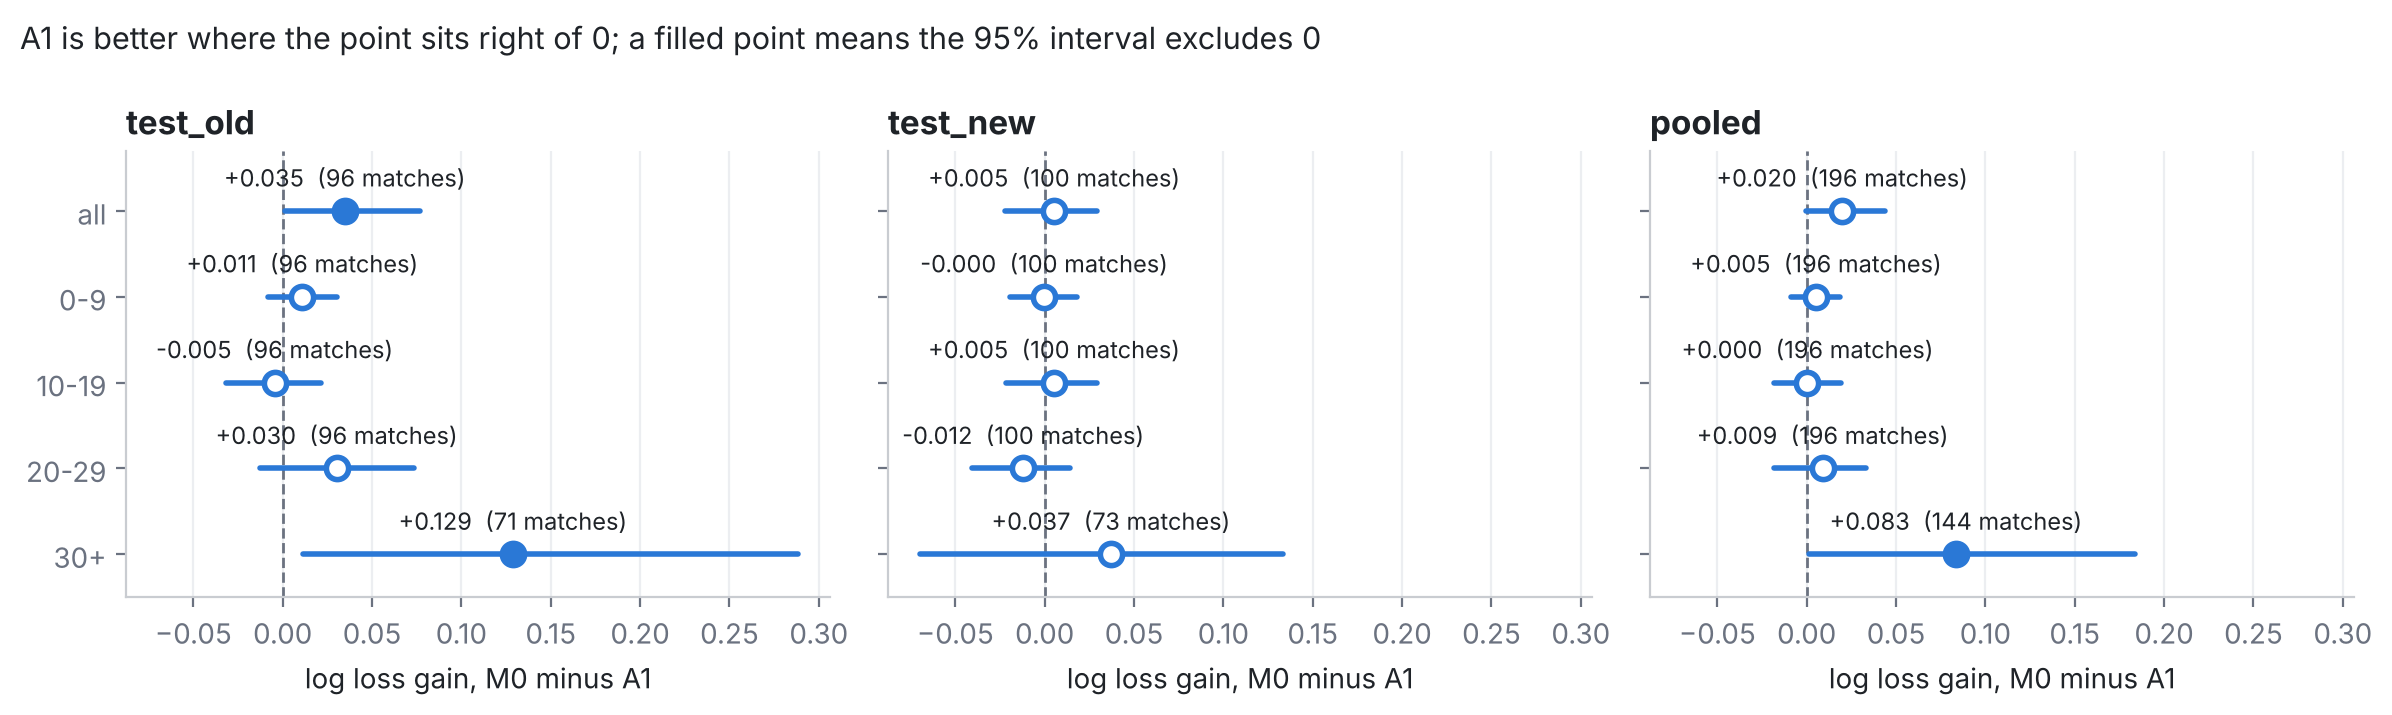

In [21]:
# The log loss gain of A1 over M0 by phase, with 95% intervals
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#1f2328", "#6b7280"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c9ccd1", "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
order = [p for p, _ in PHASES][::-1]
for ax, sname in zip(axes, SET_MASK):
    sub = {r["phase"]: r for r in RES if r["set"] == sname}
    ax.axvline(0, color=MUTED, lw=1, ls="--")
    for i, ph in enumerate(order):
        m, lo, hi = sub[ph]["ll_gain"]; trusted = lo > 0 or hi < 0
        ax.plot([lo, hi], [i, i], color=BLUE, lw=2, solid_capstyle="round")
        ax.plot(m, i, "o", ms=8, color=BLUE, mfc=BLUE if trusted else "white", mew=2)
        ax.text(m, i + 0.22, f"{m:+.3f}  ({sub[ph]['matches']} matches)", ha="center", va="bottom", color=INK, fontsize=8.5)
    ax.set_yticks(range(len(order)), order); ax.set_ylim(-0.5, len(order) - 0.3)
    ax.set_title(f"{sname}", color=INK, loc="left", fontweight="bold")
    ax.set_xlabel("log loss gain, M0 minus A1")
    ax.grid(axis="x", color="#eceef1", lw=0.8)
fig.suptitle("A1 is better where the point sits right of 0; a filled point means the 95% interval excludes 0",
             x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout(); plt.show()

## 7. Calibration

A model is calibrated when, among the moments it says 70%, Radiant wins about 70% of the time. The plots show the observed Radiant win rate against the predicted probability.

* **Curve:** a loess smoother (local linear regression with tricube weights, each point using the nearest 75% of rows), drawn only between the 2nd and 98th percentile of the predictions, where data exist.
* **Band:** 95% interval of the curve from 1,000 resamples of whole matches.
* **Points:** observed rate in 10 groups of equal size (sorted by prediction).
* **Strip below:** how the predictions are spread.

Two summary numbers come from two logistic fits of the outcome on logit(p):

* the **calibration intercept** a, from P(win) = σ(a + logit p) with the slope fixed at 1. It measures calibration-in-the-large: 0 is ideal, above 0 means Radiant wins more often than predicted on average, below 0 less often;
* the **calibration slope** b, from P(win) = σ(a′ + b · logit p). 1 is ideal; below 1 means the predictions are too extreme (too close to 0 or 1), above 1 means they are too timid (too close to 50%).

In [22]:
# 7.1 Calibration tools, with a self-test
class Loess:
    """Local linear loess of y on p at fixed grid points; weights let a match resample reuse the same neighbour order."""
    def __init__(self, p, grid, span=0.75):
        self.p, self.grid, self.span = p, grid, span
        self.D = np.abs(p[None, :] - grid[:, None])
        self.order = np.argsort(self.D, axis=1)
        self.Dsorted = np.take_along_axis(self.D, self.order, 1)
    def fit(self, y, w=None):
        w = np.ones(len(self.p)) if w is None else w
        cw = np.cumsum(w[self.order], 1)
        k = np.minimum((cw < self.span * w.sum()).sum(1), len(self.p) - 1)
        h = np.maximum(self.Dsorted[np.arange(len(self.grid)), k], 1e-9) * (1 + 1e-9)
        K = np.clip(1 - (self.D / h[:, None]) ** 3, 0, None) ** 3 * w[None, :]
        x = self.p[None, :] - self.grid[:, None]
        S0, S1, S2 = K.sum(1), (K * x).sum(1), (K * x * x).sum(1)
        T0, T1 = (K * y).sum(1), (K * x * y).sum(1)
        return np.clip((S2 * T0 - S1 * T1) / (S0 * S2 - S1 ** 2), 0, 1)

def recalibration(y, p, w=None):
    """Calibration intercept (slope fixed at 1) and calibration slope, by weighted Newton steps."""
    w = np.ones(len(y)) if w is None else w; x = np.log(p / (1 - p))
    a = 0.0
    for _ in range(50):
        q = 1 / (1 + np.exp(-(a + x))); step = (w * (y - q)).sum() / (w * q * (1 - q)).sum(); a += step
        if abs(step) < 1e-10: break
    X = np.column_stack([np.ones_like(x), x]); beta = np.zeros(2)
    for _ in range(100):
        q = 1 / (1 + np.exp(-X @ beta)); H = (X * (w * q * (1 - q))[:, None]).T @ X
        step = np.linalg.solve(H, X.T @ (w * (y - q))); beta += step
        if np.abs(step).max() < 1e-10: break
    return a, beta[1]

def match_weights(matches, B, seed):
    """B rows of weights: how many times each row's match is drawn in a resample of whole matches."""
    u, inv = np.unique(matches, return_inverse=True)
    k = np.random.default_rng(seed).integers(0, len(u), (B, len(u)))
    counts = np.stack([np.bincount(r, minlength=len(u)) for r in k])
    return counts[:, inv].astype(float)

# self-test: a straight line is recovered exactly; integer weights equal duplicated rows; a slow loop agrees
_r = np.random.default_rng(0); _p = _r.uniform(0.1, 0.9, 400); _g = np.linspace(0.2, 0.8, 7)
assert np.allclose(Loess(_p, _g).fit(0.2 + 0.5 * _p), 0.2 + 0.5 * _g)
_y = (_r.uniform(size=400) < _p).astype(float); _w = _r.integers(0, 3, 400).astype(float)
_dup = np.repeat(np.arange(400), _w.astype(int))
assert np.allclose(Loess(_p, _g).fit(_y, _w), Loess(_p[_dup], _g).fit(_y[_dup]))
def _slow(p, y, g0, span=0.75):
    d = np.abs(p - g0); h = np.sort(d)[int(np.ceil(span * len(p))) - 1]
    k = np.where(d <= h, (1 - (d / (h * (1 + 1e-9))) ** 3) ** 3, 0)
    X = np.column_stack([np.ones_like(p), p - g0]); beta = np.linalg.solve(X.T @ (X * k[:, None]), X.T @ (k * y))
    return min(max(beta[0], 0), 1)
assert np.allclose(Loess(_p, _g).fit(_y), [_slow(_p, _y, g) for g in _g], atol=1e-6)
_pb = _r.uniform(0.05, 0.95, 50000); _yb = (_r.uniform(size=50000) < _pb).astype(float)
_a, _b = recalibration(_yb, _pb); assert abs(_a) < 0.05 and abs(_b - 1) < 0.05, (_a, _b)
print(f"self-test passed (50,000 simulated calibrated rows: intercept {_a:+.3f}, slope {_b:.3f})")

self-test passed (50,000 simulated calibrated rows: intercept +0.010, slope 1.000)


In [23]:
# 7.2 Curves, bands and summary numbers
B_CAL = 1000
MODELS = [("A1", "p_model", BLUE, "o", "-"), ("M0", "p_baseline", ORANGE, "s", "--")]

def calibration_block(mask, seed):
    y, g = y_te[mask], mid_te[mask]; W = match_weights(g, B_CAL, seed); out = {}
    for name, col, *_ in MODELS:
        p = TE[col].to_numpy()[mask]
        grid = np.linspace(*np.quantile(p, [0.02, 0.98]), 60); lo = Loess(p, grid)
        boot = np.stack([lo.fit(y, w) for w in W])
        rc = np.array([recalibration(y, p, w) for w in W])
        srt = np.argsort(p, kind="mergesort"); bins = np.array_split(srt, 10)
        out[name] = {"grid": grid, "curve": lo.fit(y), "band": np.quantile(boot, [.025, .975], axis=0),
                     "bins": [(p[b].mean(), y[b].mean()) for b in bins], "p": p,
                     "rc": recalibration(y, p), "rc_ci": np.quantile(rc, [.025, .975], axis=0)}
    return {"models": out, "matches": len(np.unique(g)), "rows": int(mask.sum())}

CAL = {}
for i, sname in enumerate(SET_MASK):
    for j, (ph, f) in enumerate(PHASES):
        CAL[(sname, ph)] = calibration_block(SET_MASK[sname] & f(t_te), seed=100 + 10 * i + j)
print("calibration curves and bands computed for", len(CAL), "set x phase cells")

calibration curves and bands computed for 15 set x phase cells


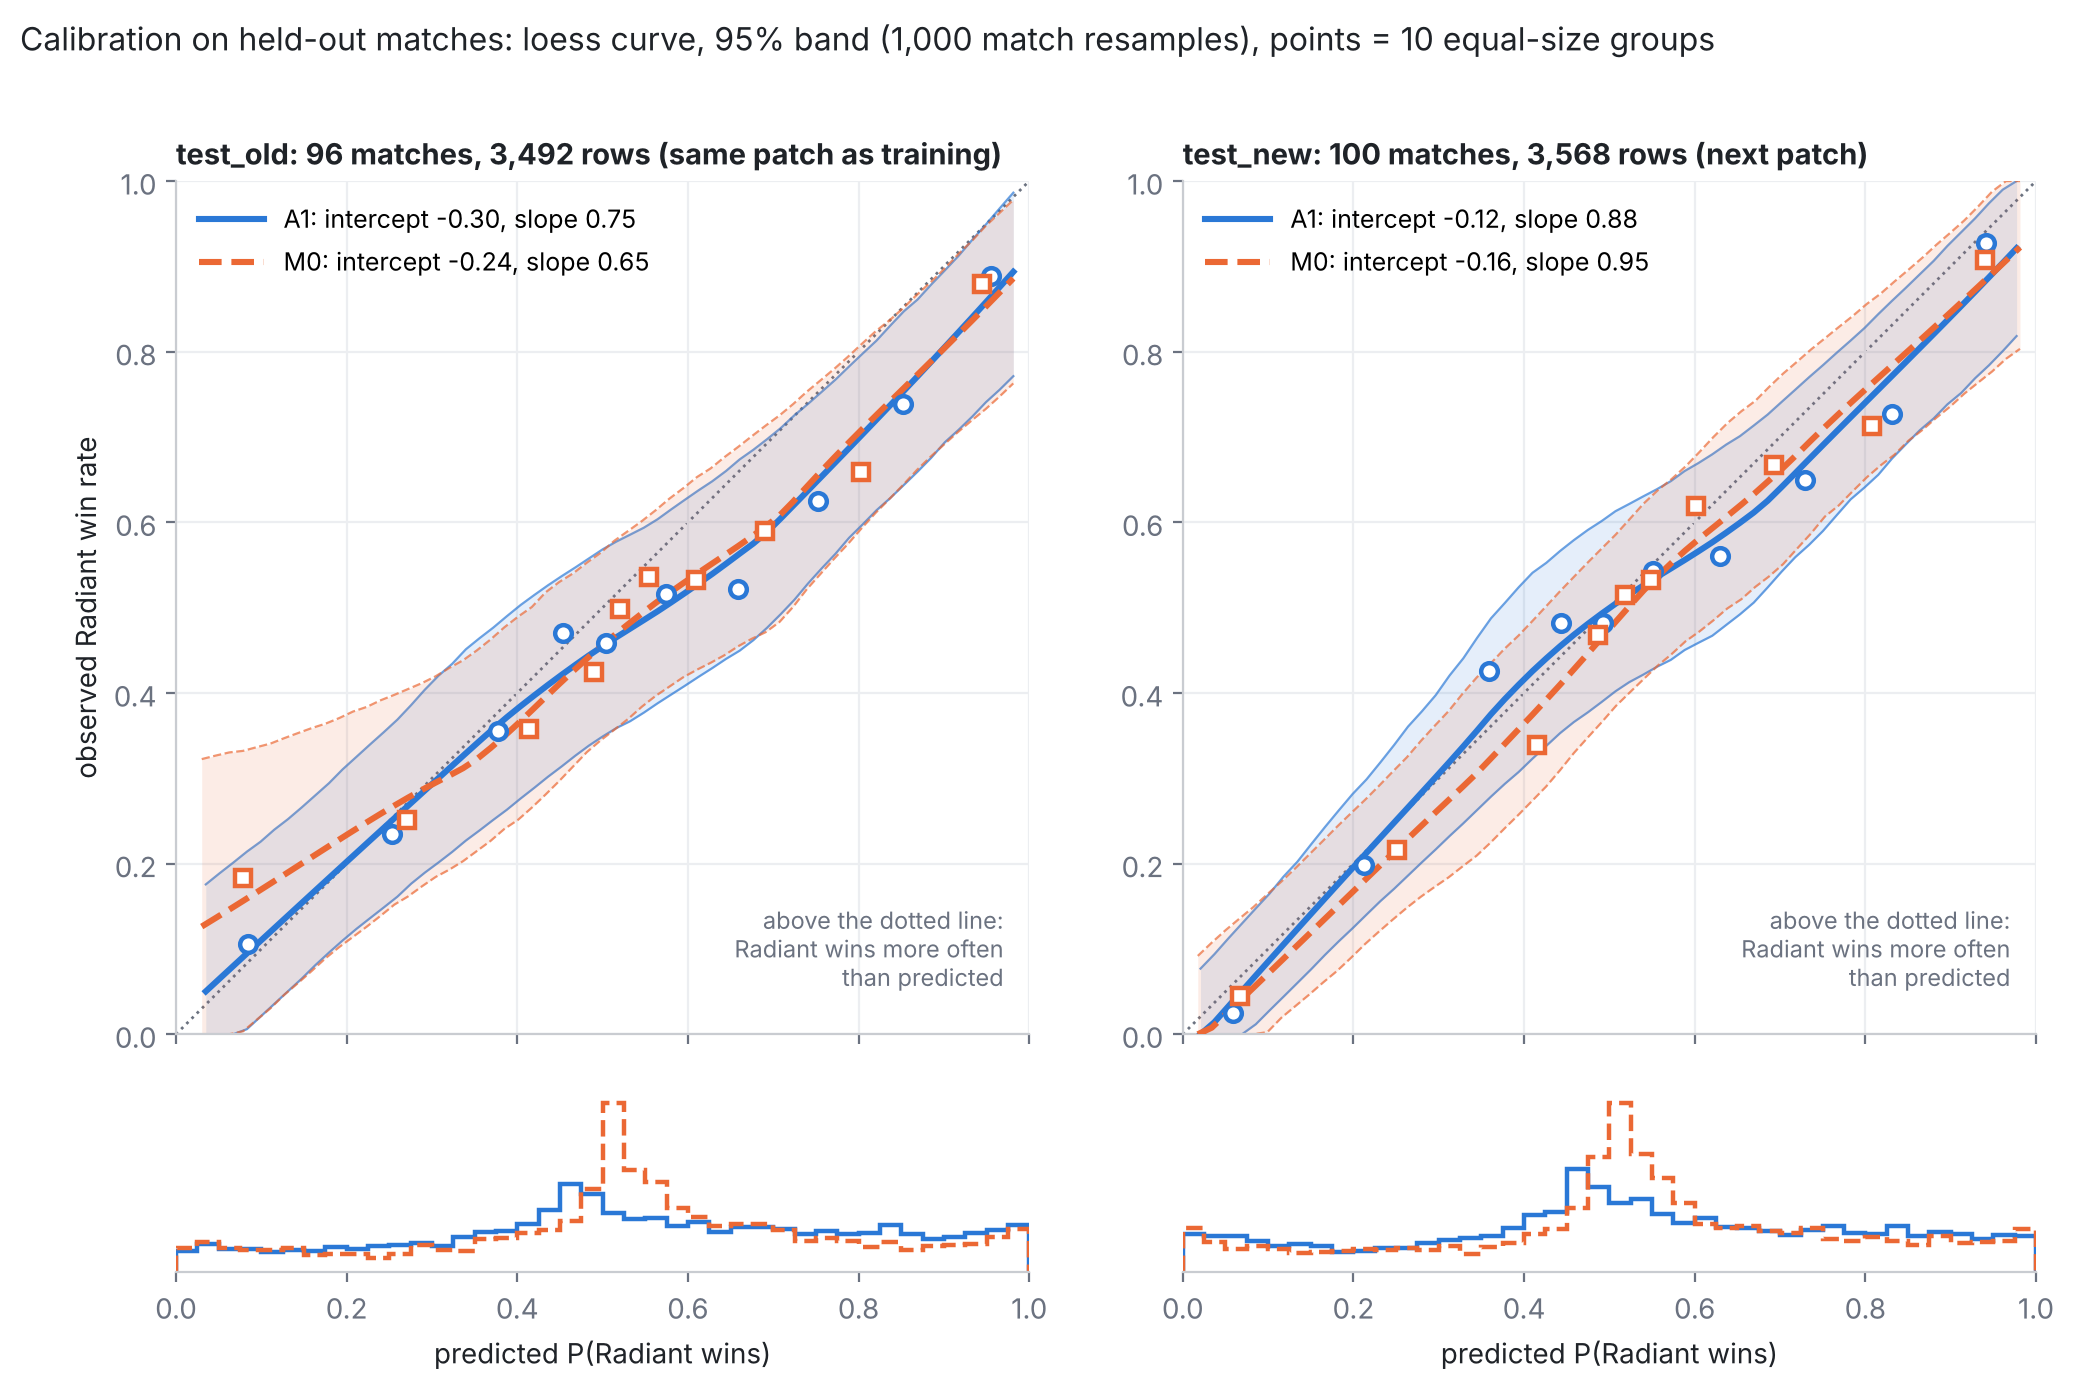

In [24]:
# 7.3 Main figure: one panel per test set, both models
def draw(ax, block, title, legend=True):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":", zorder=1)
    for name, _, color, marker, ls in MODELS:
        c = block["models"][name]; a, b = c["rc"]
        ax.fill_between(c["grid"], *c["band"], color=color, alpha=0.12, lw=0, zorder=2)
        for edge in c["band"]:
            ax.plot(c["grid"], edge, color=color, lw=0.8, alpha=0.7, ls=ls, zorder=2)
        ax.plot(c["grid"], c["curve"], color=color, lw=2.2, ls=ls, zorder=3,
                label=f"{name}: intercept {a:+.2f}, slope {b:.2f}")
        bx, by = zip(*c["bins"])
        ax.plot(bx, by, marker, ms=6, color=color, mfc="white", mew=1.6, zorder=4)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
    ax.grid(color="#eceef1", lw=0.8); ax.set_title(title, loc="left", color=INK, fontweight="bold", fontsize=10.5)
    if legend: ax.legend(loc="upper left", frameon=False, fontsize=9, handlelength=2.6)

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 2, height_ratios=[5, 1], hspace=0.08, wspace=0.18)
for k, sname in enumerate(["test_old", "test_new"]):
    blk = CAL[(sname, "all")]
    ax = fig.add_subplot(gs[0, k]); hx = fig.add_subplot(gs[1, k], sharex=ax)
    label = "same patch as training" if sname == "test_old" else "next patch"
    draw(ax, blk, f"{sname}: {blk['matches']} matches, {blk['rows']:,} rows ({label})")
    ax.text(0.97, 0.05, "above the dotted line:\nRadiant wins more often\nthan predicted", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=8.5, color=MUTED)
    ax.tick_params(labelbottom=False)
    if k == 0: ax.set_ylabel("observed Radiant win rate")
    for name, _, color, _, ls in MODELS:
        hx.hist(blk["models"][name]["p"], bins=np.linspace(0, 1, 41), histtype="step", color=color, lw=1.6, ls=ls, density=True)
    hx.set_yticks([]); hx.spines["left"].set_visible(False); hx.set_xlabel("predicted P(Radiant wins)")
fig.suptitle("Calibration on held-out matches: loess curve, 95% band (1,000 match resamples), points = 10 equal-size groups",
             x=0.06, ha="left", color=INK, fontsize=11.5)
plt.show()

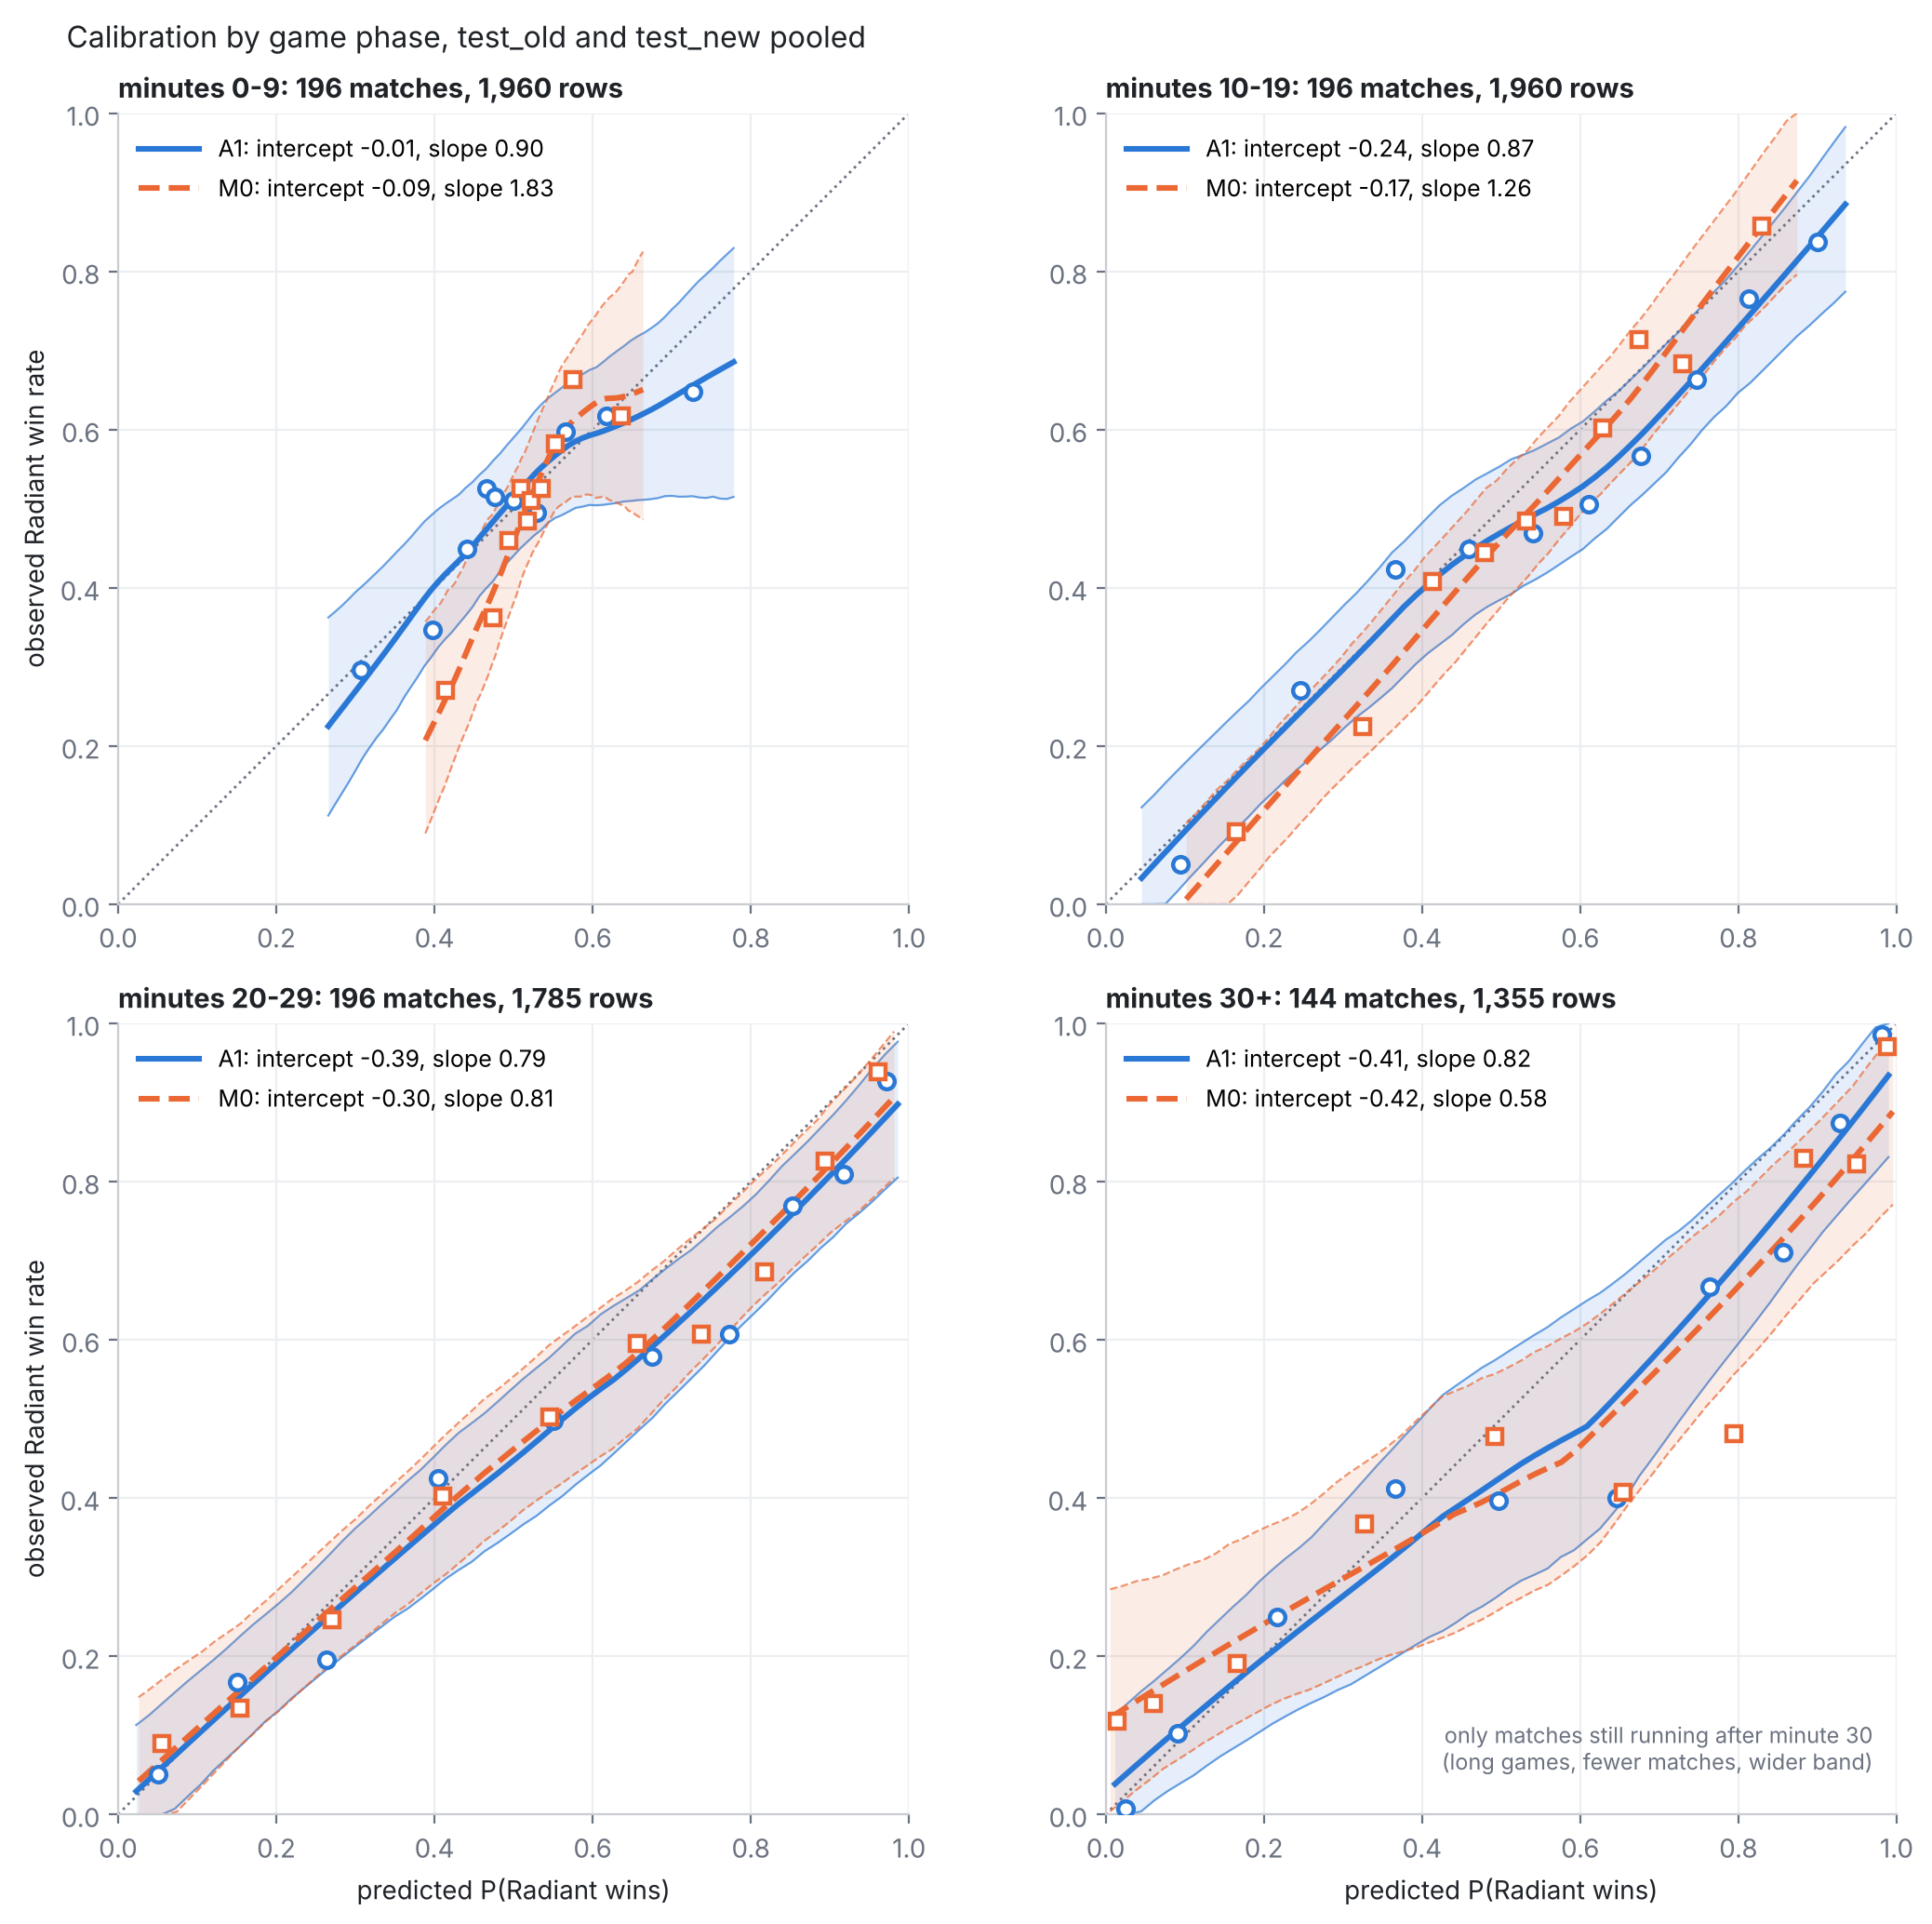

In [25]:
# 7.4 By phase (both test sets pooled; each phase panel uses only the rows of that phase)
fig, axes = plt.subplots(2, 2, figsize=(11, 10.5))
for ax, (ph, _) in zip(axes.ravel(), PHASES[1:]):
    blk = CAL[("pooled", ph)]
    draw(ax, blk, f"minutes {ph}: {blk['matches']} matches, {blk['rows']:,} rows")
    if ph == "30+":
        ax.text(0.97, 0.05, "only matches still running after minute 30\n(long games, fewer matches, wider band)",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=8.5, color=MUTED)
for ax in axes[1]: ax.set_xlabel("predicted P(Radiant wins)")
for ax in axes[:, 0]: ax.set_ylabel("observed Radiant win rate")
fig.suptitle("Calibration by game phase, test_old and test_new pooled", x=0.06, ha="left", color=INK, fontsize=11.5)
fig.tight_layout(); plt.show()

In [26]:
# 7.5 Calibration intercept and slope with 95% intervals (1,000 match resamples)
CAL_TABLE = pd.DataFrame([{
    "set": s, "phase": ph, "matches": blk["matches"],
    **{f"{m} intercept": f"{blk['models'][m]['rc'][0]:+.2f} [{blk['models'][m]['rc_ci'][0][0]:+.2f}, {blk['models'][m]['rc_ci'][1][0]:+.2f}]"
       for m in ("M0", "A1")},
    **{f"{m} slope": f"{blk['models'][m]['rc'][1]:.2f} [{blk['models'][m]['rc_ci'][0][1]:.2f}, {blk['models'][m]['rc_ci'][1][1]:.2f}]"
       for m in ("M0", "A1")}}
    for (s, ph), blk in CAL.items()]).set_index(["set", "phase"])
CAL_TABLE[["matches", "M0 intercept", "A1 intercept", "M0 slope", "A1 slope"]]

matches          M0 intercept          A1 intercept  \
set      phase                                                        
test_old all         96  -0.24 [-0.73, +0.27]  -0.30 [-0.79, +0.20]   
         0-9         96  -0.10 [-0.51, +0.32]  -0.03 [-0.46, +0.40]   
         10-19       96  -0.23 [-0.64, +0.18]  -0.34 [-0.79, +0.12]   
         20-29       96  -0.42 [-0.96, +0.14]  -0.54 [-1.08, -0.01]   
         30+         71  -0.36 [-1.39, +0.69]  -0.56 [-1.45, +0.25]   
test_new all        100  -0.16 [-0.60, +0.28]  -0.12 [-0.56, +0.34]   
         0-9        100  -0.09 [-0.49, +0.32]  +0.01 [-0.40, +0.45]   
         10-19      100  -0.11 [-0.49, +0.30]  -0.14 [-0.57, +0.30]   
         20-29      100  -0.18 [-0.69, +0.33]  -0.24 [-0.81, +0.31]   
         30+         73  -0.50 [-1.67, +0.65]  -0.25 [-1.31, +0.76]   
pooled   all        196  -0.20 [-0.51, +0.13]  -0.21 [-0.53, +0.12]   
         0-9        196  -0.09 [-0.37, +0.19]  -0.01 [-0.29, +0.28]   
         10-19      196  -0.17 [-0.44, +0.14]  -0.24 [-0.55, +0.10]   
         20-29      196  -0.30 [-0.69, +0.11]  -0.39 [-0.80, +0.02]   
         30+        144  -0.42 [-1.10, +0.40]  -0.41 [-1.03, +0.26]   

                         M0 slope           A1 slope  
set      phase                                        
test_old all    0.65 [0.36, 1.05]  0.75 [0.53, 1.04]  
         0-9    1.88 [0.55, 3.40]  1.01 [0.41, 1.68]  
         10-19  1.08 [0.62, 1.65]  0.78 [0.49, 1.13]  
         20-29  0.67 [0.41, 1.05]  0.73 [0.49, 1.07]  
         30+    0.48 [0.23, 0.91]  0.78 [0.52, 1.23]  
test_new all    0.95 [0.67, 1.41]  0.88 [0.67, 1.21]  
         0-9    1.79 [0.37, 3.61]  0.79 [0.13, 1.53]  
         10-19  1.49 [0.99, 2.23]  0.98 [0.66, 1.41]  
         20-29  0.99 [0.70, 1.44]  0.87 [0.61, 1.24]  
         30+    0.70 [0.50, 1.24]  0.87 [0.65, 1.43]  
pooled   all    0.78 [0.57, 1.08]  0.81 [0.66, 1.01]  
         0-9    1.83 [0.86, 3.01]  0.90 [0.44, 1.42]  
         10-19  1.26 [0.91, 1.69]  0.87 [0.66, 1.14]  
         20-29  0.81 [0.61, 1.09]  0.79 [0.61, 1.03]  
         30+    0.58 [0.39, 0.87]  0.82 [0.63, 1.16]

## 8. Prediction table

One row per held-out match and minute: `match_id`, `minute`, `p_model` (A1), `p_baseline` (M0), `radiant_win`. Rows are in the order of the matches (test_old, then test_new) and of the minutes.

In [27]:
PRED = TE.rename(columns={"t": "minute"})[["match_id", "minute", "p_model", "p_baseline", "radiant_win"]]
assert len(PRED) == 7060 and PRED.match_id.nunique() == 196 and not PRED.duplicated(["match_id", "minute"]).any()
PRED.to_csv("predictions_heldout.csv", index=False, float_format="%.9g", lineterminator="\n")
print(f"saved predictions_heldout.csv: {len(PRED)} rows, {PRED.match_id.nunique()} matches")
PRED.head(10)

saved predictions_heldout.csv: 7060 rows, 196 matches


,match_id,minute,p_model,p_baseline,radiant_win
0,8740188210,0,0.469197,0.518739,1
1,8740188210,1,0.499576,0.524069,1
2,8740188210,2,0.529257,0.537461,1
3,8740188210,3,0.543977,0.534224,1
4,8740188210,4,0.619182,0.569129,1
5,8740188210,5,0.596464,0.559530,1
6,8740188210,6,0.529054,0.528416,1
7,8740188210,7,0.534498,0.531046,1
8,8740188210,8,0.485017,0.533797,1
9,8740188210,9,0.481878,0.507575,1


## 9. Comments on the results

Numbers are log loss unless stated. "Gain" is M0 minus A1, so a positive gain means A1 is better. Brackets are 95% intervals from resampling whole matches. The cell after this text checks every number quoted here that comes from the tables above, so a rerun that changes them stops the notebook.

### Differences I would trust (interval excludes 0)

1. **On test_old (same patch, 96 matches) A1 beats the baseline.** Log loss 0.598 against 0.633, gain +0.035 [+0.001, +0.077]; Brier gain +0.011 [+0.001, +0.021]. The lower ends of both intervals are close to 0. The sign of the gain is supported; its size is not pinned down.
2. **The gain sits late in the game.** After minute 30 the gain is +0.129 [+0.011, +0.289] on test_old and +0.083 [+0.001, +0.183] pooled over both test sets. On test_old the Brier gain at minutes 20-29 also excludes 0 (+0.013 [+0.0005, +0.024]). The 30+ rows come only from matches that lasted past minute 30, so they describe long games, not the average match.

### Differences I would not trust

3. **On test_new (next patch, 100 matches) the two models cannot be told apart**, overall (+0.005 [−0.022, +0.029]) and in every phase. With intervals about ±0.025 wide, this sample could only have detected a gain of roughly that size. It cannot say whether A1's edge fades because the game changed or because 100 matches are too few. The test_new matches are also easier for both models (M0 0.565 against 0.633 on test_old), so the levels of the two sets should not be compared. One series has games in both test sets.
4. **Before minute 30 no log loss difference is trusted** in any set. Pooled: 0-9 +0.005, 10-19 +0.000, 20-29 +0.009, all intervals containing 0. In the first ten minutes both models are close to a coin flip (0.676 and 0.671, against 0.693). A1 does not beat the gold-lead baseline before minute 30.
5. **Pooled over both test sets the overall gain is +0.020 [−0.0005, +0.044].** The interval just reaches 0, so the overall improvement is likely but not shown.

### What the calibration plots show

6. **M0's one fixed weight on the gold lead shows in its curves.** After minute 30 M0 is too extreme: pooled slope 0.58 [0.39, 0.87], an interval that excludes 1. In minutes 0-9 its point slope is 1.83, which means too timid, but the interval is wide (0.86 to 3.01) and contains 1; the 0-9 panel of section 7.4 shows the steep shape. A 1,000-gold lead means far more at minute 8 than at minute 40, and M0 cannot express that. A1's weight on the gold lead falls with time (`gold_adv_dec`), and its pooled slope stays between 0.79 and 0.90 in every phase.
7. **The two models are close elsewhere.** At minutes 20-29 their slopes are about equal (pooled 0.81 for M0, 0.79 for A1). On test_new M0's overall slope is closer to 1 than A1's (0.95 against 0.88). A1's overall slope is 0.81 [0.66, 1.01] pooled and 0.75 [0.53, 1.04] on test_old: the point estimates suggest A1 is somewhat too extreme, but the intervals reach 1. A recalibration step would have to be fitted on out-of-fold predictions of train_tune, not on these test sets, and then tested on new matches; it was not done.
8. **Calibration intercepts are negative in most cells** (pooled −0.21 for A1 and −0.20 for M0). On held-out rows A1 predicted Radiant at 0.54 on average and M0 at 0.53, while Radiant won 0.50 of the rows. The intervals contain 0, so this may be chance.

### Caveats that apply to every number above

* The unit of evidence is the match: 96 and 100 matches per test set, not 3,500 rows. That is why the intervals are wide.
* The tables show 15 cells per metric and two metrics. The cells overlap (pooled contains both sets, "all" contains the phases), so they are not 30 independent tests, but with this many a cell can exclude 0 by chance. The phase rows are descriptive; the headline is the overall gain per test set.
* Matches of the same series are resampled independently, as the brief asks. Games of one series are related, so the intervals may be slightly too narrow. In a simulation run while building the evaluation code (not reproduced in this notebook), this bootstrap covered the true value 93% of the time for a nominal 95%.
* A1 was confirmed for submission after it and other candidate models had been scored on these test sets (section 3). Its test numbers are therefore somewhat optimistic for a model chosen this way.

### Bottom line

On later matches of the patch it was trained on, A1 does better than the baseline, mostly after minute 30. The lower bound of that gain is close to 0, and A1 was picked after the test sets had been seen. Its probabilities avoid the baseline's clearest calibration fault, overconfidence late in the game. After a patch change no difference is detectable in 100 matches. Before minute 30 A1 does not beat the gold-lead baseline.

In [28]:
# Check that every number quoted in section 9 equals the tables above (rounded as quoted)
R = {(r["set"], r["phase"]): r for r in RES}
def near(x, q, d): return round(x, d) == q or abs(x - q) <= 0.5 * 10 ** -d + 1e-12
def chk(x, q, d, what):
    assert near(x, q, d), f"section 9 quotes {q} for {what}, the table gives {x}"
checks = [
    (R["test_old", "all"]["ll_A1"][0], 0.598, 3, "A1 log loss test_old"), (R["test_old", "all"]["ll_M0"][0], 0.633, 3, "M0 log loss test_old"),
    (R["test_old", "all"]["ll_gain"][0], 0.035, 3, "gain test_old"), (R["test_old", "all"]["ll_gain"][1], 0.001, 3, "gain test_old low"),
    (R["test_old", "all"]["ll_gain"][2], 0.077, 3, "gain test_old high"),
    (R["test_old", "all"]["br_gain"][0], 0.011, 3, "Brier gain test_old"), (R["test_old", "all"]["br_gain"][1], 0.001, 3, "Brier low"),
    (R["test_old", "all"]["br_gain"][2], 0.021, 3, "Brier high"),
    (R["test_old", "30+"]["ll_gain"][0], 0.129, 3, "gain test_old 30+"), (R["test_old", "30+"]["ll_gain"][1], 0.011, 3, "low"),
    (R["test_old", "30+"]["ll_gain"][2], 0.289, 3, "high"),
    (R["pooled", "30+"]["ll_gain"][0], 0.083, 3, "gain pooled 30+"), (R["pooled", "30+"]["ll_gain"][1], 0.001, 3, "low"),
    (R["pooled", "30+"]["ll_gain"][2], 0.183, 3, "high"),
    (R["test_old", "20-29"]["br_gain"][0], 0.013, 3, "Brier gain 20-29"), (R["test_old", "20-29"]["br_gain"][1], 0.0005, 4, "low"),
    (R["test_old", "20-29"]["br_gain"][2], 0.024, 3, "high"),
    (R["test_new", "all"]["ll_gain"][0], 0.005, 3, "gain test_new"), (R["test_new", "all"]["ll_gain"][1], -0.022, 3, "low"),
    (R["test_new", "all"]["ll_gain"][2], 0.029, 3, "high"), (R["test_new", "all"]["ll_M0"][0], 0.565, 3, "M0 test_new"),
    (R["pooled", "0-9"]["ll_gain"][0], 0.005, 3, "pooled 0-9"), (R["pooled", "10-19"]["ll_gain"][0], 0.000, 3, "pooled 10-19"),
    (R["pooled", "20-29"]["ll_gain"][0], 0.009, 3, "pooled 20-29"),
    (R["pooled", "0-9"]["ll_M0"][0], 0.676, 3, "M0 0-9"), (R["pooled", "0-9"]["ll_A1"][0], 0.671, 3, "A1 0-9"),
    (R["pooled", "all"]["ll_gain"][0], 0.020, 3, "pooled gain"), (R["pooled", "all"]["ll_gain"][1], -0.0005, 4, "low"),
    (R["pooled", "all"]["ll_gain"][2], 0.044, 3, "high"),
]
for x, q, d, what in checks: chk(x, q, d, what)
# intervals said to exclude 0 or contain 0
for key, metric, excl in [(("test_old", "all"), "ll_gain", True), (("test_old", "all"), "br_gain", True), (("test_old", "30+"), "ll_gain", True),
                          (("pooled", "30+"), "ll_gain", True), (("test_old", "20-29"), "br_gain", True), (("test_new", "all"), "ll_gain", False),
                          (("pooled", "all"), "ll_gain", False)] + [((s, ph), "ll_gain", False) for s in ("test_old", "test_new", "pooled")
                                                                     for ph in ("0-9", "10-19", "20-29")] + \
                         [(("test_new", ph), m, False) for ph in ("all", "0-9", "10-19", "20-29", "30+") for m in ("ll_gain", "br_gain")]:
    lo, hi = R[key][metric][1:]
    assert (lo > 0 or hi < 0) == excl, (key, metric, lo, hi)
C = lambda s, ph, m: CAL[(s, ph)]["models"][m]
cal_checks = [(C("pooled", "0-9", "M0")["rc"][1], 1.83), (C("pooled", "0-9", "M0")["rc_ci"][0][1], 0.86), (C("pooled", "0-9", "M0")["rc_ci"][1][1], 3.01),
              (C("pooled", "30+", "M0")["rc"][1], 0.58), (C("pooled", "30+", "M0")["rc_ci"][0][1], 0.39), (C("pooled", "30+", "M0")["rc_ci"][1][1], 0.87),
              (C("pooled", "all", "A1")["rc"][1], 0.81), (C("pooled", "all", "A1")["rc_ci"][0][1], 0.66), (C("pooled", "all", "A1")["rc_ci"][1][1], 1.01),
              (C("test_old", "all", "A1")["rc"][1], 0.75), (C("test_old", "all", "A1")["rc_ci"][0][1], 0.53), (C("test_old", "all", "A1")["rc_ci"][1][1], 1.04),
              (C("pooled", "all", "A1")["rc"][0], -0.21), (C("pooled", "all", "M0")["rc"][0], -0.20)]
for x, q in cal_checks: chk(x, q, 2, "calibration number")
a1_slopes = [C("pooled", ph, "A1")["rc"][1] for ph in ("0-9", "10-19", "20-29", "30+")]
assert 0.785 <= min(a1_slopes) and max(a1_slopes) < 0.905, a1_slopes
for m in ("A1", "M0"):
    lo, hi = C("pooled", "all", m)["rc_ci"][:, 0]; assert lo < 0 < hi
assert sum(C(s, ph, m)["rc"][0] < 0 for s in SET_MASK for ph, _ in PHASES for m in ("A1", "M0")) >= 20   # "most cells"
chk(TE.p_model.mean(), 0.54, 2, "mean A1 prediction"); chk(TE.p_baseline.mean(), 0.53, 2, "mean M0 prediction"); chk(TE.radiant_win.mean(), 0.50, 2, "Radiant row win rate")
print(f"all {len(checks) + len(cal_checks) + 5} numbers quoted in section 9 match the tables")

# numbers added after the reader check
chk(C("pooled", "20-29", "M0")["rc"][1], 0.81, 2, "M0 slope 20-29"); chk(C("pooled", "20-29", "A1")["rc"][1], 0.79, 2, "A1 slope 20-29")
chk(C("test_new", "all", "M0")["rc"][1], 0.95, 2, "M0 slope test_new"); chk(C("test_new", "all", "A1")["rc"][1], 0.88, 2, "A1 slope test_new")
lo, hi = C("pooled", "30+", "M0")["rc_ci"][:, 1]; assert hi < 1                      # excludes 1
for s_, ph_, m_ in [("pooled", "0-9", "M0"), ("pooled", "all", "A1"), ("test_old", "all", "A1")]:
    lo, hi = C(s_, ph_, m_)["rc_ci"][:, 1]; assert lo < 1 <= hi or lo <= 1 < hi, (s_, ph_, m_, lo, hi)   # contains 1
half = (R["test_new", "all"]["ll_gain"][2] - R["test_new", "all"]["ll_gain"][1]) / 2; assert 0.02 < half < 0.03, half
print("reader-check additions also match")

all 48 numbers quoted in section 9 match the tables
reader-check additions also match
